# Qwen-assisted cleaning and labelling of the oral image data

The notebook first **de-duplicates** the web-scraped images in `data/raw/external`. It finds exact copies (MD5) and near-duplicates (64-bit perceptual hash), including across class folders, and keeps the highest-resolution copy of each group.

It then builds one YOLO dataset with five classes (`Calculus`, `Caries`, `Hypodontia`, `Mouth_Ulcer`, `Tooth_Discoloration`). `Normal` images are kept as empty-label backgrounds. Each image takes the route that fits what its source already tells us:

| Route | Images | What happens |
|---|---|---|
| `gt` | `roboflow_oral` (human boxes for every class) | The dataset's own boxes are used (polygons become their bounding box, `gingivitis` is dropped). **No model request.** |
| `gt_check` | `dentalai`, `zenodo` (human boxes for caries only) | The dataset's caries boxes are used. The model does one **light check** for the other four conditions and boxes them only when it has no doubt. |
| `known` | `kaggle_oral` condition folders | The folder says which condition is present. The label step is skipped: the model is told the condition is there and **must** be boxed. It may add other conditions, but only with high confidence. |
| `label` | `kaggle_oral/Normal`, `mendeley_noncaries`, other datasets | **Label** (conservative, high-confidence findings only), then **box** the conditions found. `mendeley_noncaries` is a caries-free dataset, so `Caries` is not offered. |
| `web` | de-duplicated `data/raw/external` images | **Screen** (is it a usable close-up photo of teeth?), then label and box as above. Accepted images are copied to `data/raw/external_clean/<class>/`. |

Every request is sent with **thinking off** (`enable_thinking: false`).

**What fights false findings and bad boxes:**

- The label prompt is conservative ("a false alarm is worse than a miss"). Each finding gives its visual evidence first, then a confidence. Only `high` findings are kept (`MIN_CONFIDENCE`).
- A short guide explains how to tell the three look-alikes apart. Calculus is material **added** on the tooth, caries is tooth **lost** (a hole), and discoloration is **colour** only, on a smooth, intact surface. A list of things that are not conditions (shadows, fillings, slightly yellow teeth and so on) goes with every prompt.
- Box coordinates are read as **0-1000 relative to the image**. This was measured against human boxes (see **Box check**). The old `auto` mode switched to pixels whenever a single value went above 1000, and that moved every box in the image. Duplicate boxes are merged and at most `MAX_BOXES` are kept, which stops answers that loop. The label step's evidence (e.g. "dark cavity in a lower left molar") is passed to the box prompt.

Up to `CONCURRENCY` images are worked on at once. Each image's requests run one after another, so there are never more than `CONCURRENCY` requests in flight.

**Before running, set the API key.** Either add `LLAMA_SWAP_API_KEY=...` to the repo's `.env` file (gitignored, loaded by the first cell), or set the environment variable before starting VS Code or Jupyter.

**Resuming.** Every answer is appended to `data/interim/Daniel/qwen_pipeline/<step>__<model>.jsonl` as soon as it arrives. You can interrupt the kernel, or lose it, at any point. Re-running continues from the last saved answer. Failed requests are retried on the next run. The **Write outputs** cell rebuilds `labels.csv`, `external_clean` and the YOLO folder from these saved answers, and it can be run at any time, including halfway through.

| Output | Contents |
|---|---|
| `data/raw/external_clean/<class>/*.jpg` + `manifest.csv` | de-duplicated web images that passed the screen |
| `data/interim/Daniel/qwen_pipeline/external_dedup.csv` | every external file with its duplicate group and keep/drop decision |
| `data/processed/qwen_labels/Daniel/labels.csv` | one row per image file: dataset, route, path, MD5, multi-hot labels, the model's reason, box counts |
| `data/processed/qwen_labels/Daniel/yolo/{images,labels}/` + `data.yaml` | YOLO dataset (one file per unique image, named by MD5) |

### Settings

You can change any setting in the **Parameters** cell, through an environment variable set before the kernel starts, or with papermill (`-p NAME value`):

| Setting | Env var | Default | Meaning |
|---|---|---|---|
| `CONCURRENCY` | `QWEN_CONCURRENCY` | `2` | images worked on at once = maximum requests in flight |
| `LIMIT` | `QWEN_LIMIT` | none | maximum images to process in this run (e.g. `20` for a trial run) |
| `MODEL` | `QWEN_MODEL` | `qwen3.8-flash-next-mxfp4` | model name as llama-swap lists it |
| `API_BASE` | `QWEN_API_BASE` | `http://192.168.1.148:8080/v1` | OpenAI-compatible endpoint |
| `API_KEY_ENV` | `QWEN_API_KEY_ENV` | `LLAMA_SWAP_API_KEY` | name of the env var holding the key |
| `RUN_SCREEN` / `RUN_LABEL` / `RUN_BOXES` / `RUN_CHECK` | `QWEN_RUN_SCREEN` ... | `True` | `False` = don't send that step; images wait at it |
| `MIN_CONFIDENCE` | `QWEN_MIN_CONFIDENCE` | `high` | `medium` also keeps "probably" findings (more labels, more false alarms) |
| `BOX_EVAL_N` | `QWEN_BOX_EVAL_N` | `0` | images for the optional **Box check** against human boxes (e.g. `40`) |
| `WORK` / `OUT` / `CLEAN_DIR` | `QWEN_WORK_DIR` / `QWEN_OUT_DIR` / `QWEN_CLEAN_DIR` | see cell | caches / outputs / accepted web images, e.g. for a test run elsewhere |

For example, in PowerShell: `$env:QWEN_CONCURRENCY=6; $env:QWEN_LIMIT=20`. With papermill: `papermill qwen_clean_and_label.ipynb out.ipynb -p CONCURRENCY 6 -p LIMIT 20`.

> Except for the `gt` route, the labels and boxes are **model predictions, not ground truth**. Check the sample grids, and review a sample by hand (`view_yolo_boxes.py`) before training on them.

## 0. Setup

In [1]:
import os, io, re, json, time, base64, hashlib, shutil, threading, random, warnings
from pathlib import Path
from collections import Counter
from concurrent.futures import ThreadPoolExecutor, wait, FIRST_COMPLETED

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from PIL import Image, ImageOps
from scipy.fft import dctn
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from tqdm.auto import tqdm
from IPython.display import display

Image.MAX_IMAGE_PIXELS = None
warnings.filterwarnings("ignore", module="PIL")          # odd palettes / corrupt EXIF in web images: harmless
pd.set_option("display.width", 160)


def find_repo_root():
    # Find the Deep-Learning-WIU repo (the folder containing shared/conditions.yaml). Tries, in order:
    #  1. upwards from $DLWIU_ROOT, the kernel's working directory and the notebook's folder (VS Code: __vsc_ipynb_file__);
    #  2. the notebook's path re-rooted under this machine's home / OneDrive (a Jupyter server started elsewhere,
    #     e.g. in C:\Jupyter, may receive the client's path);
    #  3. up to two levels below the working directory;
    #  4. a Deep-Learning-WIU* folder up to four levels under ~/Documents, ~/Desktop, ~/OneDrive or ~.
    def search_up(start):
        for p in [start, *start.parents]:
            if (p / "shared" / "conditions.yaml").exists():
                return p.resolve()
        return None

    starts = [Path(os.environ["DLWIU_ROOT"])] if os.environ.get("DLWIU_ROOT") else []
    starts.append(Path.cwd())
    nb_dir = Path(globals()["__vsc_ipynb_file__"]).parent if "__vsc_ipynb_file__" in globals() else None
    if nb_dir is not None:
        starts.append(nb_dir)
    for s in starts:
        if (root := search_up(s)) is not None:
            return root
    home = Path.home()
    if nb_dir is not None:
        parts = nb_dir.parts[1:]                                  # drop the drive / anchor
        for base in [home, home / "OneDrive"]:
            for i in range(len(parts)):
                if (root := search_up(base.joinpath(*parts[i:]))) is not None:
                    return root
    for pattern in ["*/shared/conditions.yaml", "*/*/shared/conditions.yaml"]:
        if hits := sorted(Path.cwd().glob(pattern)):
            return hits[0].parents[1].resolve()
    for base in [home / "Documents", home / "Desktop", home / "OneDrive" / "Documents", home / "OneDrive", home]:
        for depth in range(4):
            if base.is_dir() and (hits := sorted(base.glob("*/" * depth + "Deep-Learning-WIU*/shared/conditions.yaml"))):
                return hits[0].parents[1].resolve()
    raise FileNotFoundError(
        f"Could not find the Deep-Learning-WIU repo (cwd: {Path.cwd()}). Before this cell, run: "
        "os.environ['DLWIU_ROOT'] = 'C:/path/to/Deep-Learning-WIU'")


def load_dotenv(path):
    # Minimal .env reader (KEY=value lines). Variables already set in the environment win.
    if not path.exists():
        return
    for line in path.read_text(encoding="utf-8").splitlines():
        line = line.strip()
        if line and not line.startswith("#") and "=" in line:
            k, v = line.split("=", 1)
            if v.strip():
                os.environ.setdefault(k.strip(), v.strip().strip('"').strip("'"))


ROOT = find_repo_root()
load_dotenv(ROOT / ".env")
print("repo root:", ROOT)

repo root: C:\Users\Dani\Documents\School\AI Inno W DL\Deep-Learning-WIU


C:\Users\Dani\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Parameters

In [2]:
def _env(name, default, cast=str):
    v = os.environ.get(name)
    if v is None or v.strip() == "":
        return default
    if cast is bool:
        return v.strip().lower() in {"1", "true", "yes", "y", "on"}
    if cast in (list, dict):
        return json.loads(v)
    return cast(v)


# --- LLM server --------------------------------------------------------------------------------------------
API_BASE = _env("QWEN_API_BASE", "http://192.168.1.148:8080/v1")
MODEL = _env("QWEN_MODEL", "qwen3.8-flash-next-mxfp4")
API_KEY_ENV = _env("QWEN_API_KEY_ENV", "LLAMA_SWAP_API_KEY")   # env var that holds the key (falls back to OPENAI_API_KEY)
CONCURRENCY = _env("QWEN_CONCURRENCY", 2, int)                 # max requests in flight at once
LIMIT = _env("QWEN_LIMIT", None, int)                          # max images to process this run (None = all)
TIMEOUT = _env("QWEN_TIMEOUT", 300, int)                       # seconds per request (first call may wait for a model swap)
MAX_RETRIES = _env("QWEN_MAX_RETRIES", 3, int)                 # extra attempts per image on errors / unparseable answers
MAX_TOKENS = _env("QWEN_MAX_TOKENS", 2048, int)                # thinking is off, so answers are short; a looping answer stops here
TEMPERATURE = _env("QWEN_TEMPERATURE", 0.0, float)
RETRY_TEMPERATURE = _env("QWEN_RETRY_TEMPERATURE", 0.7, float)  # used on retries: at 0 a looping answer loops again
JSON_MODE = _env("QWEN_JSON_MODE", True, bool)                 # send response_format={"type": "json_object"}
EXTRA_BODY = _env("QWEN_EXTRA_BODY", {}, dict)                 # extra request fields sent with every call
MAX_SIDE = _env("QWEN_MAX_SIDE", 1024, int)                    # images are downsized to this before upload (1536 measured worse)
JPEG_QUALITY = 90
MAX_CONSECUTIVE_FAILS = 10                                     # abort a step if this many images fail in a row

# --- Steps (False = don't send this step; images wait at it, cached answers are still used) -------------------
RUN_SCREEN = _env("QWEN_RUN_SCREEN", True, bool)               # web images: usable photo?
RUN_LABEL = _env("QWEN_RUN_LABEL", True, bool)                 # route "label" / "web": which conditions?
RUN_BOXES = _env("QWEN_RUN_BOXES", True, bool)                 # routes "label" / "web" / "known": boxes
RUN_CHECK = _env("QWEN_RUN_CHECK", True, bool)                 # route "gt_check": light check for non-caries conditions

# --- De-duplication / screening --------------------------------------------------------------------------------
PHASH_MAX_HAMMING = _env("QWEN_PHASH_MAX_HAMMING", 6, int)     # <= 6 of 64 bits differ -> same photo
MIN_SIDE_PX = 64                                               # drop thumbnails smaller than this
DELETE_EXTERNAL_DUPLICATES = _env("QWEN_DELETE_EXTERNAL_DUPLICATES", False, bool)  # also delete dupes from data/raw/external
ACCEPT_COLLAGES = _env("QWEN_ACCEPT_COLLAGES", False, bool)    # before/after or grid composites

# --- Labelling / boxes ---------------------------------------------------------------------------------------------
LABEL_EXCLUDE = _env("QWEN_LABEL_EXCLUDE", [], list)           # extra top-level data/raw folders NOT to label
WEB_SKIP_CLASSES = _env("QWEN_WEB_SKIP_CLASSES", ["Gingivitis"], list)  # web search folders not labelled (class not used)
MIN_CONFIDENCE = _env("QWEN_MIN_CONFIDENCE", "high")           # "high" | "medium": model findings below this are dropped
COORD_MODE = _env("QWEN_COORD_MODE", "norm1000")               # norm1000 (measured) | pixel | norm1 | auto (old heuristic)
MIN_BOX = 0.005                                                # drop boxes thinner than 0.5% of the image
MAX_BOXES = _env("QWEN_MAX_BOXES", 12, int)                    # boxes kept per model answer (answers that loop repeat boxes)
NMS_IOU = 0.6                                                  # same-class model boxes overlapping more than this are merged
INCLUDE_NORMAL_IN_YOLO = _env("QWEN_INCLUDE_NORMAL_IN_YOLO", True, bool)  # Normal images as empty-label backgrounds
SHUFFLE = _env("QWEN_SHUFFLE", True, bool)                     # work through the images in random order (all routes mixed)
BOX_EVAL_N = _env("QWEN_BOX_EVAL_N", 0, int)                   # images for the optional Box check (0 = skip)
IO_WORKERS = 8                                                 # threads for local hashing / copying
SEED = 42

In [3]:
RAW = ROOT / "data" / "raw"
EXT_DIR = RAW / "external"
CLEAN_DIR = Path(_env("QWEN_CLEAN_DIR", str(RAW / "external_clean")))
WORK = Path(_env("QWEN_WORK_DIR", str(ROOT / "data" / "interim" / "Daniel" / "qwen_pipeline")))  # indexes + caches (gitignored)
OUT = Path(_env("QWEN_OUT_DIR", str(ROOT / "data" / "processed" / "qwen_labels" / "Daniel")))      # labels.csv + YOLO (gitignored)
YOLO_DIR = OUT / "yolo"
for d in [WORK, OUT, YOLO_DIR / "images", YOLO_DIR / "labels"]:
    d.mkdir(parents=True, exist_ok=True)

LABELS = ["Normal", "Calculus", "Caries", "Hypodontia", "Mouth_Ulcer", "Tooth_Discoloration"]
BOX_CLASSES = [c for c in LABELS if c != "Normal"]                # YOLO class ids 0..4
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}

API_KEY = os.environ.get(API_KEY_ENV) or os.environ.get("OPENAI_API_KEY")
MODEL_SLUG = re.sub(r"[^A-Za-z0-9._-]+", "_", MODEL)
CONF_OK = {"high": {"high"}, "medium": {"high", "medium"}}[MIN_CONFIDENCE]
random.seed(SEED)
print(f"model {MODEL} @ {API_BASE} | concurrency {CONCURRENCY} | limit {LIMIT} | thinking off | "
      f"API key: {'set' if API_KEY else 'NOT SET (' + API_KEY_ENV + ')'}")

model qwen3.8-flash-next-mxfp4 @ http://192.168.1.148:8080/v1 | concurrency 2 | limit None | thinking off | API key: set


### Image helpers

These cells hash the images, load them, show sample grids, and keep a local index cache. The index records MD5, size and pHash per file, and is recomputed only for files whose size or modification time changed.

In [4]:
import pickle


def load_rgb(src, max_side=None):
    # Open, honour EXIF orientation, convert to RGB and optionally downsize (fast JPEG draft decode).
    im = Image.open(src)
    if max_side and im.format == "JPEG":
        im.draft("RGB", (max_side, max_side))
    im = ImageOps.exif_transpose(im).convert("RGB")
    if max_side:
        im.thumbnail((max_side, max_side), Image.LANCZOS)
    return im


def phash64(im):
    # 64-bit DCT perceptual hash as an unsigned int.
    a = np.asarray(im.convert("L").resize((32, 32), Image.LANCZOS), dtype=np.float32)
    d = dctn(a, norm="ortho")[:8, :8].flatten()
    return int(np.packbits(d > np.median(d[1:])).view(">u8")[0])


def _index_one(path, with_phash):
    st = path.stat()
    r = dict(path=str(path), size=st.st_size, mtime=st.st_mtime, md5=None, w=0, h=0, phash=0, has_phash=with_phash,
             ok=False, error=None)
    try:
        b = path.read_bytes()
        r["md5"] = hashlib.md5(b).hexdigest()
        with Image.open(io.BytesIO(b)) as im0:
            r["w"], r["h"] = im0.size
            if with_phash:
                r["phash"] = phash64(load_rgb(io.BytesIO(b), 256))
            else:
                im0.verify()
        r["ok"] = True
    except Exception as e:
        r["error"] = f"{type(e).__name__}: {e}"[:200]
    return r


def _plain(r):
    # Builtin Python types only, so the cache loads with any pandas / numpy version (no pyarrow needed).
    return {k: (v.item() if isinstance(v, np.generic) else v) for k, v in r.items()}


def index_files(paths, cache_file, with_phash):
    # MD5 (+ optional pHash, size) for each file, reusing a cache keyed by path, size and mtime.
    old = {}
    if cache_file.exists():
        try:
            with open(cache_file, "rb") as f:
                data = pickle.load(f)
            if isinstance(data, pd.DataFrame):           # cache written by an older version of this cell
                data = data.to_dict("records")
            old = {r["path"]: r for r in data}
        except Exception as e:                           # unreadable / incompatible: rebuild it
            print(f"ignoring cache {cache_file.name} ({type(e).__name__}: {e})")
    recs, todo = [], []
    for p in paths:
        o = old.get(str(p))
        st = p.stat()
        if o and o["size"] == st.st_size and o["mtime"] == st.st_mtime and (o["has_phash"] or not with_phash):
            recs.append(o)
        else:
            todo.append(p)
    if todo:
        with ThreadPoolExecutor(IO_WORKERS) as ex:
            recs += list(tqdm(ex.map(lambda p: _index_one(p, with_phash), todo), total=len(todo),
                              desc=f"hashing {cache_file.stem}"))
    recs = sorted((_plain(r) for r in recs), key=lambda r: r["path"])
    with open(cache_file, "wb") as f:
        pickle.dump(recs, f)
    df = pd.DataFrame(recs)
    df["phash"] = df["phash"].astype(np.uint64)
    print(f"{cache_file.stem}: {len(df)} files ({len(todo)} newly hashed, {(~df.ok).sum()} unreadable)")
    return df


def show_grid(paths, titles=None, boxes=None, ncols=6, size=2.6, suptitle=None):
    # boxes: optional list (per image) of YOLO rows [cls, cx, cy, w, h] drawn on top.
    paths = list(paths)
    if not paths:
        print("(nothing to show)"); return
    nrows = (len(paths) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * size * 1.05), squeeze=False)
    colors = plt.cm.tab10.colors
    for ax in axes.flat:
        ax.axis("off")
    for i, p in enumerate(paths):
        ax = axes.flat[i]
        if p is None:
            continue
        try:
            im = load_rgb(p, 512)
        except Exception as e:
            ax.set_title(f"unreadable: {e}"[:40], fontsize=7); continue
        ax.imshow(im)
        if boxes is not None:
            W, H = im.size
            for c, cx, cy, bw, bh in boxes[i]:
                c = int(c)
                ax.add_patch(plt.Rectangle(((cx - bw / 2) * W, (cy - bh / 2) * H), bw * W, bh * H, fill=False,
                                           lw=2, color=colors[c % 10]))
                ax.text((cx - bw / 2) * W, (cy - bh / 2) * H, BOX_CLASSES[c], color="white", fontsize=7,
                        bbox=dict(facecolor=colors[c % 10], pad=1, lw=0), va="bottom")
        if titles is not None:
            ax.set_title(str(titles[i])[:60], fontsize=7, wrap=True)
    if suptitle:
        fig.suptitle(suptitle)
    plt.tight_layout(); plt.show()

## 1. De-duplicate `data/raw/external`

The scraper saved images under one folder per search class, and the same photo often comes back from several engines and queries, sometimes resized or recompressed. Two images count as duplicates when their perceptual hashes differ in at most `PHASH_MAX_HAMMING` bits (exact byte copies have distance 0). Duplicate pairs are joined into groups (connected components). From each group the copy with the most pixels is kept, then the largest file.

Nothing in `data/raw/external` is touched unless `DELETE_EXTERNAL_DUPLICATES = True`. The kept copies go on to the screen in step 2.

In [5]:
ext_paths = sorted(p for p in EXT_DIR.rglob("*") if p.is_file() and p.suffix.lower() in IMG_EXTS)
ext = index_files(ext_paths, WORK / "index_external.pkl", with_phash=True)
ext["file"] = ext.path.map(lambda p: Path(p).relative_to(EXT_DIR).as_posix())   # same key as manifest.csv
ext["cls"] = ext.file.str.split("/").str[0]
ext["status"] = np.where(~ext.ok, "unreadable", np.where(ext[["w", "h"]].min(axis=1) < MIN_SIDE_PX, "too_small", "ok"))

if hasattr(np, "bitwise_count"):                  # numpy >= 2.0
    popcount = np.bitwise_count
else:                                             # older numpy: count bits per byte with a lookup table
    _POP8 = np.array([bin(i).count("1") for i in range(256)], np.uint8)
    popcount = lambda x: _POP8[np.ascontiguousarray(x).view(np.uint8)].reshape(*x.shape, 8).sum(-1, dtype=np.uint8)

good = ext[ext.status == "ok"].copy()
H = good.phash.to_numpy(np.uint64)
rows, cols = [np.empty(0, np.int64)], [np.empty(0, np.int64)]
CHUNK = 512
for s in range(0, len(H), CHUNK):
    d = popcount(H[s:s + CHUNK, None] ^ H[None, :])           # Hamming distance to every image
    i, j = np.nonzero(d <= PHASH_MAX_HAMMING)
    i += s
    m = i < j
    rows.append(i[m]); cols.append(j[m])
rows, cols = np.concatenate(rows), np.concatenate(cols)
graph = coo_matrix((np.ones(len(rows), np.int8), (rows, cols)), shape=(len(H), len(H)))
_, good["group"] = connected_components(graph, directed=False)

good["area"] = good.w * good.h
best = good.sort_values(["group", "area", "size", "file"], ascending=[True, False, False, True]).drop_duplicates("group")
good["keep"] = good.index.isin(best.index)
good["dup_of"] = np.where(good.keep, "", good.group.map(best.set_index("group").file))
good["group_size"] = good.group.map(good.group.value_counts())
good["group_classes"] = good.group.map(good.groupby("group").cls.agg(lambda s: "|".join(sorted(set(s)))))

ext = ext.join(good[["group", "dup_of", "group_size", "group_classes"]])
ext["keep"] = ext.index.isin(good.index[good.keep])
ext.loc[(ext.status == "ok") & ~ext.keep, "status"] = "duplicate"
ext.drop(columns=["phash", "has_phash"]).to_csv(WORK / "external_dedup.csv", index=False)

summary = pd.crosstab(ext.cls, ext.status, margins=True, margins_name="total")
display(summary)
multi = good[good.keep & good.group_classes.str.contains("|", regex=False)]
print(f"{len(good)} readable images -> {good.keep.sum()} unique "
      f"({len(rows)} duplicate pairs, {(good.group_size > 1).sum()} images in {good[good.group_size > 1].group.nunique()} groups); "
      f"{len(multi)} unique photos were scraped under more than one class")

index_external: 21000 files (0 newly hashed, 3 unreadable)


status,duplicate,ok,unreadable,total
cls,,,,
Calculus,131,2868,1,3000
Caries,749,2250,1,3000
Gingivitis,1188,1812,0,3000
Hypodontia,1521,1479,0,3000
Mouth_Ulcer,1678,1321,1,3000
Normal,971,2029,0,3000
Tooth_Discoloration,1791,1209,0,3000
total,8029,12968,3,21000


20997 readable images -> 12968 unique (15091 duplicate pairs, 12021 images in 3992 groups); 3843 unique photos were scraped under more than one class


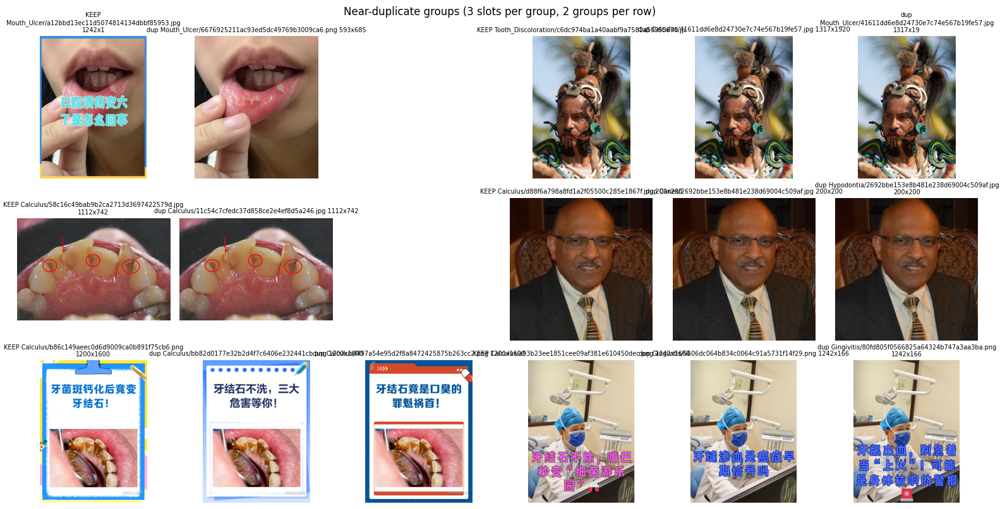

In [6]:
# Show some near-duplicate groups (not byte-identical) to check the threshold is not merging different photos.
near = good[good.group_size > 1].groupby("group").filter(lambda g: g.md5.nunique() > 1)
sample_groups = random.sample(sorted(near.group.unique()), min(6, near.group.nunique()))
paths, titles = [], []
for g in sample_groups:
    m = near[near.group == g].sort_values("keep", ascending=False).head(3)
    for _, r in m.iterrows():
        paths.append(r.path); titles.append(f"{'KEEP' if r.keep else 'dup'} {r.file} {r.w}x{r.h}")
    paths += [None] * (3 - len(m)); titles += [""] * (3 - len(m))
if paths:
    show_grid(paths, titles, ncols=6, suptitle="Near-duplicate groups (3 slots per group, 2 groups per row)")
else:
    print("no near-duplicates (only byte-identical copies, or none)")

In [7]:
if DELETE_EXTERNAL_DUPLICATES:
    dupes = ext[ext.status == "duplicate"]
    for p in dupes.path:
        Path(p).unlink(missing_ok=True)
    man_path = EXT_DIR / "manifest.csv"
    if man_path.exists():
        man = pd.read_csv(man_path)
        man[~man.file.isin(set(dupes.file))].to_csv(man_path, index=False)
    print(f"deleted {len(dupes)} duplicate files from {EXT_DIR}")
else:
    print("data/raw/external left untouched (set DELETE_EXTERNAL_DUPLICATES = True to delete the duplicates)")

data/raw/external left untouched (set DELETE_EXTERNAL_DUPLICATES = True to delete the duplicates)


## 2. LLM client

This is a small OpenAI-compatible client for llama-swap. It does not depend on the `openai` package.

- **Thinking is always off.** Every request carries `chat_template_kwargs: {"enable_thinking": false}`, whatever `EXTRA_BODY` holds.
- Each image is EXIF-rotated, downsized to `MAX_SIDE` and sent as a base64 JPEG.
- HTTP 429 (llama-swap's concurrency limit) is waited out and does not use up a retry.
- `Cache` holds one step's answers. Each answer is appended to that step's JSONL file as soon as it arrives. Lines from a killed run that were only half written are skipped on load.
- `cached_call` returns the saved answer if there is one. Otherwise it asks the model, retrying errors and unparseable answers with backoff (and a higher temperature, so a looping answer comes out differently), and saves the result.
- `run_queue` works on `CONCURRENCY` images at once. It stops immediately on 401/403 (bad key), and after `MAX_CONSECUTIVE_FAILS` failed images in a row (for example, the server is down or the model name is wrong). When you interrupt it, running workers stop before their next request.

In [8]:
class FatalAPIError(RuntimeError):
    pass


class StepFailed(RuntimeError):
    # One request failed after all retries. The image is skipped for now and retried on the next run.
    pass


STOP = threading.Event()          # set on interrupt so workers stop before their next request
_tls = threading.local()
NO_THINKING = {"enable_thinking": False}   # sent with every request: thinking mode is never used


def _session():
    s = getattr(_tls, "session", None)
    if s is None:
        s = _tls.session = requests.Session()
        if API_KEY:
            s.headers["Authorization"] = f"Bearer {API_KEY}"
    return s


def encode_image(path):
    im = load_rgb(path, MAX_SIDE)
    buf = io.BytesIO()
    im.save(buf, "JPEG", quality=JPEG_QUALITY)
    return "data:image/jpeg;base64," + base64.b64encode(buf.getvalue()).decode("ascii"), im.size


def chat(messages):
    # Retries (see cached_call) use RETRY_TEMPERATURE, so an answer that looped or was cut off comes out differently.
    temp = TEMPERATURE if getattr(_tls, "attempt", 0) == 0 else max(TEMPERATURE, RETRY_TEMPERATURE)
    body = dict(model=MODEL, messages=messages, temperature=temp, max_tokens=MAX_TOKENS, **EXTRA_BODY)
    body["chat_template_kwargs"] = {**body.get("chat_template_kwargs", {}), **NO_THINKING}
    body.pop("reasoning_effort", None)
    if JSON_MODE:
        body["response_format"] = {"type": "json_object"}
    for _ in range(300):                                 # 429 = llama-swap is at its concurrency limit: wait, don't fail
        r = _session().post(f"{API_BASE}/chat/completions", json=body, timeout=TIMEOUT)
        if r.status_code != 429 or STOP.is_set():
            break
        STOP.wait(2)
    if r.status_code in (401, 403):
        raise FatalAPIError(f"HTTP {r.status_code}: {r.text[:300]}  (is {API_KEY_ENV} set correctly?)")
    if r.status_code >= 400:
        raise RuntimeError(f"HTTP {r.status_code}: {r.text[:300]}")
    choice = r.json()["choices"][0]
    content = choice["message"].get("content") or ""
    if not content.strip():
        raise ValueError(f"empty answer (finish_reason={choice.get('finish_reason')})")
    return content


def ask_image(path, prompt, system=None):
    # Returns (answer text, (width, height) of the image that was sent).
    url, size = encode_image(path)
    msgs = [{"role": "system", "content": system}] if system else []
    msgs.append({"role": "user", "content": [{"type": "image_url", "image_url": {"url": url}},
                                             {"type": "text", "text": prompt}]})
    return chat(msgs), size


def parse_json(text):
    text = re.sub(r"<think>.*?</think>", "", text, flags=re.S)    # harmless with thinking off; kept for other servers
    text = re.sub(r"^.*</think>", "", text, flags=re.S)
    text = re.sub(r"```(?:json)?", "", text).strip()
    try:
        return json.loads(text)
    except json.JSONDecodeError:
        pass
    for pat in (r"\{.*\}", r"\[.*\]"):
        m = re.search(pat, text, re.S)
        if m:
            try:
                return json.loads(m.group(0))
            except json.JSONDecodeError:
                continue
    raise ValueError(f"no JSON in answer (cut off or looping?): {text[:200]!r}")


def as_bool(v):
    if isinstance(v, bool):
        return v
    if isinstance(v, (int, float)):
        return bool(v)
    if isinstance(v, str) and v.strip().lower() in {"true", "yes", "y", "1"}:
        return True
    if isinstance(v, str) and v.strip().lower() in {"false", "no", "n", "0"}:
        return False
    return None


class Cache:
    # One step's answers, persisted as JSONL: one line per request, appended (and closed) as soon as it finishes.
    def __init__(self, step):
        self.step = step
        self.path = WORK / f"{step}__{MODEL_SLUG}.jsonl"
        self.lock = threading.Lock()
        self.done = {}
        if self.path.exists():
            with self.path.open(encoding="utf-8") as f:
                for line in f:
                    try:
                        rec = json.loads(line)
                    except json.JSONDecodeError:        # half-written line from a killed run
                        continue
                    if rec.get("ok"):
                        self.done[rec["key"]] = rec

    def __contains__(self, key):
        return key in self.done

    def get(self, key):
        return self.done.get(key)

    def put(self, rec):
        with self.lock:
            with self.path.open("a", encoding="utf-8") as f:
                f.write(json.dumps(rec, ensure_ascii=False) + "\n")
            if rec["ok"]:
                self.done[rec["key"]] = rec


def cached_call(cache, key, fn, send=True):
    # The saved answer, or ask the model (with retries) and save it. None = not answered yet and sending is off.
    rec = cache.get(key)
    if rec is not None or not send:
        return rec
    if not API_KEY:
        raise FatalAPIError(f"No API key: set {API_KEY_ENV} in the environment or in {ROOT / '.env'} and re-run setup.")
    err = None
    for attempt in range(MAX_RETRIES + 1):
        if STOP.is_set():
            raise StepFailed("interrupted")
        t0 = time.time()
        _tls.attempt = attempt
        try:
            rec = dict(key=key, ok=True, model=MODEL, **fn())
            rec["secs"] = round(time.time() - t0, 1)
            cache.put(rec)
            return rec
        except FatalAPIError:
            raise
        except Exception as e:
            err = f"{type(e).__name__}: {e}"[:500]
            if attempt < MAX_RETRIES:
                STOP.wait(min(60, 3 * 2 ** attempt))
    cache.put(dict(key=key, ok=False, model=MODEL, error=err))
    raise StepFailed(f"{cache.step}: {err}")


def last_attempt():
    return getattr(_tls, "attempt", 0) >= MAX_RETRIES


def run_queue(items, process_fn, desc="images"):
    # process_fn(item) -> dict(state=...) for each item, CONCURRENCY items at a time. Returns a Counter of states.
    STOP.clear()
    stream, pending, counts, fails_in_row = iter(items), {}, Counter(), 0
    ex = ThreadPoolExecutor(max_workers=CONCURRENCY)
    try:
        with tqdm(total=len(items), desc=desc) as bar:
            while True:
                while len(pending) < CONCURRENCY and (it := next(stream, None)) is not None:
                    pending[ex.submit(process_fn, it)] = it
                if not pending:
                    break
                finished, _ = wait(pending, return_when=FIRST_COMPLETED)
                for fut in finished:
                    it = pending.pop(fut)
                    try:
                        counts[fut.result()["state"]] += 1      # re-raises FatalAPIError / unexpected errors
                        fails_in_row = 0
                    except StepFailed as e:
                        counts["failed"] += 1
                        fails_in_row += 1
                        tqdm.write(f"  failed {it['key'][:10]}: {str(e)[:160]}")
                        if fails_in_row >= MAX_CONSECUTIVE_FAILS:
                            raise RuntimeError(f"{fails_in_row} images failed in a row, stopping. Last error: {e}")
                    bar.update(1)
                    bar.set_postfix(dict(counts))
    finally:
        STOP.set()                                       # running workers stop before their next request
        ex.shutdown(wait=False, cancel_futures=True)
    print("finished this run:", dict(counts))
    return counts

In [9]:
# Connection check: is the key accepted and does llama-swap know the model?
if not API_KEY:
    print(f"WARNING: {API_KEY_ENV} is not set; steps 2-4 can only read cached answers.")
else:
    r = _session().get(f"{API_BASE}/models", timeout=30)
    if r.status_code in (401, 403):
        raise FatalAPIError(f"HTTP {r.status_code}: key rejected by {API_BASE}: {r.text[:200]}")
    r.raise_for_status()
    models = [m.get("id") for m in r.json().get("data", [])]
    print(f"{len(models)} models on server")
    if MODEL not in models:
        print(f"WARNING: {MODEL!r} is not listed. Available: {models}")
    else:
        print(f"OK: {MODEL} is available")

7 models on server
OK: qwen3.8-flash-next-mxfp4 is available


## 3. The steps

- **Screen** (web images only, unchanged). Six questions: does it show real human teeth; are several teeth visible; is the mouth **unobstructed**; does the mouth **fill a large part of the frame**; is it a photograph; is it a collage? An image is accepted when the first five are yes and it is not a collage (`ACCEPT_COLLAGES` allows collages). Answers are saved under `screen_v2`. Images the earlier, looser screen (`screen`) rejected are not sent again.
- **Label** (routes `label` and `web`). The model lists only conditions it can point to. For each one it gives the **evidence** first, then the label, then a **confidence** (`high` / `medium`). Only findings at `MIN_CONFIDENCE` or above count, so the threshold can be changed later without re-asking. The prompt carries the look-alike guide and the not-a-condition list. It also passes on what the source says, as a hint: the web search term, kaggle's `Normal` folder, or mendeley's "no caries" (for mendeley, `Caries` is left out of the list altogether). Saved under `label_v4`.
- **Box** (routes `label` and `web`). The prompt names the conditions the label step found, together with its evidence, and asks for `[x1, y1, x2, y2]` on a 0-1000 scale. Box answers are saved per image *and* label set (`boxes_v2`), so an image is boxed again if its labels change.
- **Known box** (route `known`). The prompt says the dataset has confirmed the condition, so it must be boxed. If the answer has no box for it, the request is retried. Other conditions may be added, but only boxes marked `high` are kept, and the prompt warns against relabelling parts of the known condition. Saved under `known_boxes_v1`.
- **Light check** (route `gt_check`). The model is told the dataset's dentists have already marked the caries, and is asked for a quick look for the other four conditions. Only `high` boxes are kept, and they are added to the human caries boxes. A check box that lies more than half inside a human caries box is dropped (`CHECK_MAX_OVERLAP`): in testing, the model sometimes boxed the marked caries again as discoloration. Saved under `caries_check_v1`.

All model boxes are read as 0-1000 relative coordinates (`COORD_MODE`) and clipped to the image. Boxes thinner than `MIN_BOX` are dropped. Same-class boxes overlapping by more than `NMS_IOU` are merged, and at most `MAX_BOXES` are kept per answer.

YOLO class ids: `0 Calculus, 1 Caries, 2 Hypodontia, 3 Mouth_Ulcer, 4 Tooth_Discoloration` (`Normal` has no box). `Gingivitis` and `Others` are no longer used.

In [10]:
# --- Screen (web images) -------------------------------------------------------------------------------------------
SCREEN_SYSTEM = "You are a careful annotator screening web images for a dental photo dataset. Answer with JSON only."
SCREEN_PROMPT = '''Look at the image and answer:
1. "human_teeth": does it show the real teeth of a living human? (false for animals, skulls, dentures or plastic tooth models on their own, toys, drawings, cartoons, 3D renders, diagrams and X-rays)
2. "teeth_visible": are several teeth clearly visible? (false when the mouth is closed or the teeth are hidden)
3. "unobstructed": is the whole mouth clearly shown with nothing covering any part of the teeth? (false if instruments, food, text, captions, watermarks, logos, or arrows / circles / marks drawn on the image cover any of it; cheek retractors that only hold the lips back are fine)
4. "mouth_fills_frame": is the mouth the main subject and a large part of the image, i.e. a close-up where the mouth covers at least about a third of the image? (false for full faces, portraits, people at a distance and wide shots)
5. "photo": is it a real photograph? (false for illustrations, renders, infographics, X-rays / radiographs, and screenshots dominated by text)
6. "collage": is it several photos combined (before/after, side-by-side, grid)?
Reply exactly in this format: {"human_teeth": true, "teeth_visible": true, "unobstructed": true, "mouth_fills_frame": true, "photo": true, "collage": false, "reason": "at most 15 words"}'''
SCREEN_FIELDS = ["human_teeth", "teeth_visible", "unobstructed", "mouth_fills_frame", "photo", "collage"]


def screen_one(path):
    text, _ = ask_image(path, SCREEN_PROMPT, SCREEN_SYSTEM)
    js = parse_json(text)
    if not isinstance(js, dict):
        raise ValueError(f"expected an object, got {text[:200]!r}")
    out = {k: as_bool(js.get(k)) for k in SCREEN_FIELDS}
    missing = [k for k, v in out.items() if v is None]
    if missing:
        raise ValueError(f"missing {missing} in {text[:200]!r}")
    out["reason"] = str(js.get("reason", ""))[:300]
    return out


def accepted(r):
    return bool(r.get("human_teeth") and r.get("teeth_visible") and r.get("unobstructed") and r.get("mouth_fills_frame")
                and r.get("photo") and (ACCEPT_COLLAGES or not r.get("collage")))


def accepted_v1(r):
    # The first, looser screen (no unobstructed / mouth_fills_frame questions). Its rejections still count.
    return bool(r.get("human_teeth") and r.get("teeth_visible") and r.get("photo") and (ACCEPT_COLLAGES or not r.get("collage")))


# --- Shared prompt parts -------------------------------------------------------------------------------------------
SYSTEM = ("You are a cautious dental annotator labelling oral photographs for a training dataset. A false alarm is worse "
          "than a miss. Answer with JSON only.")
LABEL_INFO = {
    "Calculus": "hard tartar: a thick, rough, crusty deposit stuck ON the tooth (cream, yellow, brown or dark), along the gum "
                "line or filling the gaps between teeth, often behind the lower front teeth",
    "Caries": "tooth decay: tooth structure LOST - a hole, pit, crater or broken-down area IN a tooth, usually dark brown or "
              "black with a defined edge, on a chewing surface, between teeth or at the neck of a tooth",
    "Hypodontia": "a missing tooth: a clear gap in the row of teeth where a tooth should be (not a small space between two "
                  "teeth, not the end of the row at the edge of the photo)",
    "Mouth_Ulcer": "an open sore on the lips, cheek, tongue or gums: a round or oval patch with a white / yellow centre and a "
                   "red border",
    "Tooth_Discoloration": "the tooth COLOUR is changed but its surface is smooth and intact: teeth that are clearly yellow, "
                           "brown, grey or black, or flat stains, white mottled patches or bands on the enamel",
}
BOX_HOW = {
    "Calculus": "each tartar deposit (one box may cover a band of deposit along several neighbouring teeth)",
    "Caries": "each decayed spot or cavity, tightly around the damaged area itself",
    "Hypodontia": "each gap where a tooth is missing (the empty space between the neighbouring teeth)",
    "Mouth_Ulcer": "each ulcer, including its red border",
    "Tooth_Discoloration": "each discoloured tooth or stained area (one box may cover several neighbouring teeth that are "
                           "discoloured in the same way)",
}
TELL_APART = (
    "How to tell Calculus, Caries and Tooth_Discoloration apart - ask what happened to the tooth:\n"
    "- something ADDED on top (raised, rough, crusty, follows the gum line) -> Calculus\n"
    "- tooth MISSING material (a hole, pit or crater with depth and a dark floor, on one spot of one tooth) -> Caries\n"
    "- only the COLOUR changed (flat, smooth, glossy surface, often several teeth evenly) -> Tooth_Discoloration\n"
    "A thin flat brown line or stain is Tooth_Discoloration, not Calculus. A dark spot without a visible hole is "
    "Tooth_Discoloration, not Caries. Dark lines or dots in the grooves of the back teeth without a visible hole are "
    "staining, not Caries. Yellow crust at the gum line is Calculus, not Caries.\n")
NOT_CONDITIONS = (
    "These are NOT conditions, do not report them: slightly yellowish or off-white teeth, natural shade differences, "
    "shadows between teeth, light reflections, saliva, bubbles, food, fillings, crowns, braces, cheek retractors, "
    "lipstick, dark gum pigmentation, red or swollen gums, and any problem not in the list above.\n")
COORDS = ("Give each box as [x1, y1, x2, y2] (top-left and bottom-right corners) in integer coordinates from 0 to 1000, "
          f"relative to the image width (x) and height (y). Give at most {MAX_BOXES} boxes.\n")

ALIASES = {
    "normal": "Normal", "healthy": "Normal", "none": "Normal",
    "calculus": "Calculus", "tartar": "Calculus",
    "caries": "Caries", "cavity": "Caries", "cavities": "Caries", "decay": "Caries", "tooth decay": "Caries",
    "hypodontia": "Hypodontia", "missing teeth": "Hypodontia", "missing tooth": "Hypodontia",
    "mouth ulcer": "Mouth_Ulcer", "ulcer": "Mouth_Ulcer", "canker sore": "Mouth_Ulcer", "aphthous ulcer": "Mouth_Ulcer",
    "tooth discoloration": "Tooth_Discoloration", "tooth discolouration": "Tooth_Discoloration",
    "discoloration": "Tooth_Discoloration", "discolouration": "Tooth_Discoloration", "staining": "Tooth_Discoloration",
    "stain": "Tooth_Discoloration", "stains": "Tooth_Discoloration", "stained teeth": "Tooth_Discoloration",
    "tooth stain": "Tooth_Discoloration", "fluorosis": "Tooth_Discoloration",
}


def norm_label(x):
    if not isinstance(x, str):
        return None
    return ALIASES.get(re.sub(r"[\s_-]+", " ", x).strip().lower())


def norm_conf(x):
    x = str(x or "").strip().lower()
    return x if x in ("high", "medium", "low") else "low"


def cond_list(names):
    return "\n".join(f"- {k}: {LABEL_INFO[k]}" for k in names)


def joined(names):
    return names[0] if len(names) == 1 else ", ".join(names[:-1]) + " and " + names[-1]


# --- Model boxes -> normalised boxes -> YOLO rows ---------------------------------------------------------------
def parse_boxes(js, size, allowed):
    # [{"label", "confidence", "xyxy" (0-1 of the image)}] from a box answer; unknown labels and bad boxes are skipped.
    items = js.get("boxes", js.get("objects", [])) if isinstance(js, dict) else js
    if isinstance(items, dict):
        items = [items]
    parsed = []
    for b in items or []:
        if not isinstance(b, dict):
            continue
        lab_ = norm_label(b.get("label"))
        xy = b.get("bbox_2d") or b.get("bbox") or b.get("box")
        if lab_ in allowed and lab_ != "Normal" and isinstance(xy, (list, tuple)) and len(xy) == 4:
            try:
                parsed.append((lab_, norm_conf(b.get("confidence", "high")), [float(v) for v in xy]))
            except (TypeError, ValueError):
                continue
    if not parsed:
        return []
    mode = COORD_MODE
    if mode == "auto":
        top = max(max(xy) for *_, xy in parsed)
        mode = "pixel" if top > 1000 else "norm1" if top <= 1.0 else "norm1000"
    sx, sy = {"pixel": size, "norm1": (1, 1), "norm1000": (1000, 1000)}[mode]
    out = []
    for lab_, conf, (x1, y1, x2, y2) in parsed:
        x1, x2 = sorted((min(max(x1 / sx, 0), 1), min(max(x2 / sx, 0), 1)))
        y1, y2 = sorted((min(max(y1 / sy, 0), 1), min(max(y2 / sy, 0), 1)))
        if x2 - x1 >= MIN_BOX and y2 - y1 >= MIN_BOX:
            out.append(dict(label=lab_, confidence=conf, xyxy=[round(v, 6) for v in (x1, y1, x2, y2)]))
    return out


def box_iou(a, b):
    ix = max(0.0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0.0


def xyxy_to_row(label, xyxy):
    x1, y1, x2, y2 = xyxy
    return [BOX_CLASSES.index(label), round((x1 + x2) / 2, 6), round((y1 + y2) / 2, 6), round(x2 - x1, 6), round(y2 - y1, 6)]


def model_rows(items, allowed, required=()):
    # YOLO rows from a model answer: allowed labels only; boxes of `required` labels kept whatever their confidence,
    # the rest only at MIN_CONFIDENCE; same-class duplicates merged; at most MAX_BOXES.
    keep = []
    for b in items:
        if b["label"] not in allowed or (b["label"] not in required and b["confidence"] not in CONF_OK):
            continue
        if any(k["label"] == b["label"] and box_iou(k["xyxy"], b["xyxy"]) > NMS_IOU for k in keep):
            continue
        keep.append(b)
    return [xyxy_to_row(b["label"], b["xyxy"]) for b in keep[:MAX_BOXES]]


# --- Label (routes label / web) ------------------------------------------------------------------------------------
FINDINGS_FORMAT = ('For each condition you report, first write the visual evidence (what you see and where, a few words), '
                   'then the label, then your confidence: "high" (clearly visible, no doubt) or "medium" (probably).\n'
                   'Reply exactly in this format: {"findings": [{"evidence": "dark cavity in a lower left molar", '
                   '"label": "Caries", "confidence": "high"}], "reason": "at most 15 words"}\n'
                   'If nothing is clearly visible, reply {"findings": [], "reason": "..."}.')
LABEL_CACHE = "label_v4"          # bump when the label prompt changes (v3 and older: other prompts, 7 classes, thinking on)


def label_prompt(conds, hint=""):
    return ("Which of these dental conditions are clearly visible in this photo?\n" + cond_list(conds) + "\n"
            + hint + "Report a condition only if you can point to it in the photo. Most photos show healthy teeth or a "
            "single problem. If you are unsure, leave it out.\n" + TELL_APART + NOT_CONDITIONS + FINDINGS_FORMAT)


def label_one(path, conds, hint=""):
    text, _ = ask_image(path, label_prompt(conds, hint), SYSTEM)
    js = parse_json(text)
    if not isinstance(js, dict) or not isinstance(js.get("findings"), list):
        raise ValueError(f"no findings list in {text[:200]!r}")
    finds = []
    for f in js["findings"]:
        if isinstance(f, dict) and (lab_ := norm_label(f.get("label"))) in conds:
            finds.append(dict(label=lab_, confidence=norm_conf(f.get("confidence")), evidence=str(f.get("evidence", ""))[:200]))
    rec = dict(conds=list(conds), hint=hint, findings=finds, raw=js, reason=str(js.get("reason", ""))[:300])
    rec["labels"] = labels_of(rec)            # at the time of asking; labels_of() re-applies MIN_CONFIDENCE on read
    return rec


def labels_of(rec):
    labs = {f["label"] for f in rec.get("findings", []) if f["confidence"] in CONF_OK}
    return sorted(labs, key=LABELS.index) or ["Normal"]


# --- Box (routes label / web) ----------------------------------------------------------------------------------------
def box_prompt(labels, evidence):
    lines = [f"- {l}: {BOX_HOW[l]}" + (f" (seen: {'; '.join(evidence[l])})" if evidence.get(l) else "") for l in labels]
    return (f"This oral photo shows: {joined(labels)}.\nDraw a tight bounding box around:\n" + "\n".join(lines) + "\n"
            f"Only use these labels: {', '.join(labels)}. Box only what you can clearly see; never box healthy teeth.\n"
            + COORDS + 'Reply exactly in this format: {"boxes": [{"label": "' + labels[0] + '", "bbox_2d": [x1, y1, x2, y2]}]}')


def box_one(path, label_rec, labels):
    ev = {}
    for f in label_rec.get("findings", []):
        if f["label"] in labels and f["confidence"] in CONF_OK and f["evidence"]:
            ev.setdefault(f["label"], []).append(f["evidence"])
    text, size = ask_image(path, box_prompt(labels, ev), SYSTEM)
    js = parse_json(text)
    return dict(labels=labels, items=parse_boxes(js, size, set(labels)), raw=js)


def box_key(md5, labels):
    return md5 + "|" + "+".join(labels)


# --- Known box (route known: the dataset says which condition is present) ---------------------------------------------
def known_prompt(required):
    others = [c for c in BOX_CLASSES if c not in required]
    req, n = joined(required), len(required)
    return (f"This oral photo comes from a dataset that labels it as showing {req}. This is confirmed: {req} "
            f"{'is' if n == 1 else 'are'} present, so you must draw at least one box for {'it' if n == 1 else 'each'}.\n"
            + "\n".join(f"- {l}: {LABEL_INFO[l]}. Box {BOX_HOW[l]}." for l in required) + "\n"
            "You may also box these other conditions, but only if one is clearly visible as a separate problem and you "
            "have no doubt:\n" + cond_list(others) + "\n"
            f"Do not label parts of the {req} as another condition.\n" + TELL_APART + NOT_CONDITIONS + COORDS +
            f'Give every box a "confidence": "high" (no doubt) or "medium" (probably); boxes for {req} are always "high".\n'
            'Reply exactly in this format: {"boxes": [{"label": "' + required[0]
            + '", "bbox_2d": [x1, y1, x2, y2], "confidence": "high"}]}')


def known_one(path, required):
    text, size = ask_image(path, known_prompt(required), SYSTEM)
    js = parse_json(text)
    items = parse_boxes(js, size, set(BOX_CLASSES))
    missing = [l for l in required if not any(b["label"] == l for b in items)]
    if missing and not last_attempt():                 # it must be boxed: ask again (at a higher temperature)
        raise ValueError(f"no box for the known condition(s) {missing}: {text[:200]!r}")
    return dict(required=list(required), items=items, missing=missing, raw=js)


def known_key(md5, required):
    return md5 + "|" + "+".join(required)


# --- Light check (route gt_check: the dataset has human boxes for caries only) ------------------------------------------
CHECK_CONDS = [c for c in BOX_CLASSES if c != "Caries"]


def check_prompt(n_caries):
    marked = f"{n_caries} caries area{'s' if n_caries != 1 else ''}" if n_caries else "none in this photo"
    return (f"This oral photo comes from a tooth-decay dataset whose dentists have already marked the caries ({marked}). "
            "Do not look for caries.\nDo a quick check for these other conditions:\n" + cond_list(CHECK_CONDS) + "\n"
            "Most photos in this dataset show none of them. Report one only if it is clearly visible and you have no doubt. "
            "Dark spots, holes and brown or black areas on the teeth (above all on the chewing surfaces of the back teeth) "
            "are the caries already marked: never box them, not even as Tooth_Discoloration. Use Tooth_Discoloration only "
            "for teeth whose whole colour is clearly changed.\n"
            + NOT_CONDITIONS + COORDS +
            'Give every box a "confidence": "high" (no doubt) or "medium" (probably).\n'
            'Reply exactly in this format: {"boxes": [{"label": "Calculus", "bbox_2d": [x1, y1, x2, y2], "confidence": "high"}]}\n'
            'If none of them is clearly visible, reply {"boxes": []}.')


def check_one(path, n_caries):
    text, size = ask_image(path, check_prompt(n_caries), SYSTEM)
    js = parse_json(text)
    if not isinstance(js, (dict, list)):
        raise ValueError(f"expected an object, got {text[:200]!r}")
    return dict(items=parse_boxes(js, size, set(CHECK_CONDS)), raw=js)

## 4. Build the work list

The work list has one entry per unique image (by MD5):

- **Web images** are the de-duplicated `external` images from section 1. They start at the screen step. Images found only by a search in `WEB_SKIP_CLASSES` (`Gingivitis`) are left out: that class is no longer used, and those photos would otherwise end up as "Normal" backgrounds.
- **Dataset images** are every other top-level folder in `data/raw`, except `external`, `external_clean` and anything in `LABEL_EXCLUDE`. They skip the screen. The same bytes can appear more than once, for example zenodo's nested `Benchmarking Dataset/Benchmarking Dataset` copy. Each MD5 is then handled only once, and the answer applies to every copy.

A web image whose exact bytes are already in a dataset is treated as a dataset image. It is not screened and not copied to `external_clean`, which keeps the same photo out of two sources.

**Existing annotations** (`GT_SOURCES`) decide the route:

| Dataset | Kind | Read from | Classes used |
|---|---|---|---|
| `roboflow_oral` | `full` → route `gt` | YOLO `labels/<name>.txt` next to `images/`, class names from `data.yaml`; polygon rows become their bounding box | calculus, caries, hypodontia, tooth_discolation, ulcer (gingivitis dropped) |
| `zenodo` | `caries` → route `gt_check` | YOLO `yolo/<name>.txt` next to `images/` (classes `d` / `D` = decayed); **no file = no caries marked** | Caries |
| `dentalai` | `caries` → route `gt_check` | Supervisely `ann/<name>.json` polygons | `Caries`, `Cavity` → Caries (`Tooth` and `Crack` ignored) |

An MD5 with copies in several places takes the strongest source: `full` > `caries` > a kaggle condition folder (route `known`) > the label route. A roboflow image whose only boxes were gingivitis has no boxes left. It is left out of the YOLO set: its annotators only marked the gingivitis, so it is not a safe background.

The table shows where each image currently stands.

In [11]:
import ast

SKIP_DIRS = {"external", "external_clean", CLEAN_DIR.name, *LABEL_EXCLUDE}
label_paths = sorted(p for d in sorted(RAW.iterdir()) if d.is_dir() and d.name not in SKIP_DIRS
                     for p in d.rglob("*") if p.is_file() and p.suffix.lower() in IMG_EXTS)
ds = index_files(label_paths, WORK / "index_raw.pkl", with_phash=False)
ds["rel"] = ds.path.map(lambda p: Path(p).relative_to(RAW).as_posix())
ds["dataset"] = ds.rel.str.split("/").str[0]
ds = ds[ds.ok].reset_index(drop=True)

cand = ext[ext.status == "ok"].reset_index(drop=True)          # one kept copy per duplicate group
ds_md5 = set(ds.md5)
cand["in_dataset"] = cand.md5.isin(ds_md5)


# --- Existing annotations -------------------------------------------------------------------------------------------
# Each reader returns [(label, [x1, y1, x2, y2] as 0-1 of the image)], or None when the image has no annotation file.
ROBOFLOW_MAP = {"calculus": "Calculus", "caries": "Caries", "hypodontia": "Hypodontia", "ulcer": "Mouth_Ulcer",
                "mouth_ulcer": "Mouth_Ulcer", "tooth_discolation": "Tooth_Discoloration",
                "tooth_discoloration": "Tooth_Discoloration"}                       # gingivitis: not used
_yaml_names = {}


def _names(yaml_path):
    # Class names from a Roboflow data.yaml ("names: ['calculus', ...]"), cached per file.
    if yaml_path not in _yaml_names:
        names = []
        if yaml_path.exists():
            m = re.search(r"^names:\s*(\[.*\])", yaml_path.read_text(encoding="utf-8"), re.M)
            names = ast.literal_eval(m.group(1)) if m else []
        _yaml_names[yaml_path] = names
    return _yaml_names[yaml_path]


def _clip(b):
    x1, y1, x2, y2 = (min(max(float(v), 0.0), 1.0) for v in b)
    return [min(x1, x2), min(y1, y2), max(x1, x2), max(y1, y2)]


def _yolo_line_box(vals):
    # A YOLO row after the class id: "cx cy w h" (box) or "x1 y1 x2 y2 ..." (segmentation polygon).
    if len(vals) == 4:
        cx, cy, w, h = vals
        return _clip([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2])
    return _clip([min(vals[0::2]), min(vals[1::2]), max(vals[0::2]), max(vals[1::2])])


def gt_roboflow(path):
    p = Path(path)
    lab_file = p.parent.parent / "labels" / f"{p.stem}.txt"
    if not lab_file.exists():
        return None
    names = _names(p.parent.parent.parent / "data.yaml")
    out = []
    for line in lab_file.read_text(encoding="utf-8").split("\n"):
        v = line.split()
        if len(v) < 5 or len(v) % 2 == 0:
            continue
        c = int(float(v[0]))
        name = ROBOFLOW_MAP.get(names[c].lower()) if c < len(names) else None
        if name:
            out.append((name, _yolo_line_box([float(x) for x in v[1:]])))
    return out


def gt_zenodo(path):
    p = Path(path)
    lab_file = p.parent.parent / "yolo" / f"{p.stem}.txt"
    if not lab_file.exists():
        return []                                    # unannotated image: the annotators marked no caries
    return [("Caries", _yolo_line_box([float(x) for x in v[1:]]))
            for v in map(str.split, lab_file.read_text(encoding="utf-8").split("\n")) if len(v) >= 5 and len(v) % 2]


def gt_dentalai(path):
    p = Path(path)
    ann = p.parent.parent / "ann" / f"{p.name}.json"
    if not ann.exists():
        return None
    j = json.loads(ann.read_text(encoding="utf-8"))
    W, H = j["size"]["width"], j["size"]["height"]
    out = []
    for o in j.get("objects", []):
        pts = (o.get("points") or {}).get("exterior") or []
        if o.get("classTitle") in ("Caries", "Cavity") and len(pts) >= 2:
            xs, ys = [q[0] for q in pts], [q[1] for q in pts]
            out.append(("Caries", _clip([min(xs) / W, min(ys) / H, max(xs) / W, max(ys) / H])))
    return out


GT_SOURCES = {"roboflow_oral": ("full", gt_roboflow), "zenodo": ("caries", gt_zenodo), "dentalai": ("caries", gt_dentalai)}


def read_gt(dataset, path):
    kind, fn = GT_SOURCES.get(dataset, (None, None))
    if fn is None:
        return None, None
    try:
        return kind, fn(path)
    except Exception as e:                           # unreadable annotation: treat the image as unannotated
        print(f"  annotation error {Path(path).name}: {type(e).__name__}: {e}")
        return kind, None


with ThreadPoolExecutor(IO_WORKERS) as _ex:
    _gt = list(tqdm(_ex.map(lambda a: read_gt(*a), zip(ds.dataset, ds.path)), total=len(ds), desc="annotations"))
ds["gt_kind"] = [k for k, _ in _gt]
ds["human"] = [g for _, g in _gt]


# --- What the source says (used for the route and as a hint in the label prompt) --------------------------------------
# Whole-dataset rules for datasets whose folders carry no class.
DATASET_RULES = {
    "mendeley_noncaries": dict(
        exclude={"Caries"},
        hint="The source dataset states that this photo shows no tooth decay, so Caries is not in the list: treat dark "
             "spots or lines in the grooves as staining, or as nothing if they are faint.\n"),
}
NORMAL_HINT = ("The source dataset labels this photo as Normal (healthy teeth). It may still show a problem, but report one "
               "only if it is clearly visible.\n")


def folder_labels(rel):
    parts = rel.split("/")
    if parts[0] in DATASET_RULES or parts[0] in GT_SOURCES:
        return set()
    return {l for l in map(norm_label, parts[1:-1]) if l}          # class folders in the path, e.g. kaggle's "Mouth ulcer"


ds["folders"] = ds.rel.map(folder_labels)


def md5_route(g):
    # One route per unique image, from all its copies: full annotations > caries annotations > class folder > label.
    full = [gt for k, gt in zip(g["gt_kind"], g["human"]) if k == "full" and gt is not None]
    car = [gt for k, gt in zip(g["gt_kind"], g["human"]) if k == "caries" and gt is not None]
    folders = set().union(*g["folders"])
    dsets = sorted(set(g["dataset"]))
    if full:
        return dict(mode="gt", gt=max(full, key=len))
    if car:
        return dict(mode="gt_check", gt=max(car, key=len))
    known = sorted(folders - {"Normal"}, key=LABELS.index)
    if known:
        return dict(mode="known", known=known, orig=" / ".join(known) + " (class folder in the source dataset)")
    exclude = set().union(*(DATASET_RULES.get(d, {}).get("exclude", set()) for d in dsets))
    hint = "".join(DATASET_RULES[d]["hint"] for d in dsets if d in DATASET_RULES)
    if "Normal" in folders:
        hint += NORMAL_HINT
    return dict(mode="label", conds=[c for c in BOX_CLASSES if c not in exclude], hint=hint,
                orig=("Normal (class folder in the source dataset)" if "Normal" in folders
                      else "; ".join(d for d in dsets if d in DATASET_RULES)))


ROUTE = {m: md5_route(g) for m, g in tqdm(ds.groupby("md5", sort=False), desc="routes")}
web_hint = {}
for m, g in zip(cand.md5, cand.group_classes):
    if m not in ds_md5 and isinstance(g, str) and g:
        qs = g.split("|")
        web_hint[m] = (" / ".join(qs), f"This photo was found by a web search for: {' / '.join(qs)}. Search results are "
                                       "often wrong, so judge only what you can see.\n")
ORIG = {m: r.get("orig", "") for m, r in ROUTE.items()} | {m: h[0] + " (web search term)" for m, h in web_hint.items()}

items = ([dict(key=m, path=p, file=f, source="web", screen=True, mode="label", conds=list(BOX_CLASSES),
               hint=web_hint.get(m, ("", ""))[1])
          for m, p, f, g in zip(cand.md5, cand.path, cand.file, cand.group_classes)
          if m not in ds_md5 and not set(str(g).split("|")) <= set(WEB_SKIP_CLASSES)]
         + [dict(key=m, path=p, file=None, source="dataset", screen=False, **ROUTE[m])
            for m, p in ds.drop_duplicates("md5")[["md5", "path"]].itertuples(index=False)])
ITEM = {it["key"]: it for it in items}

SCREEN, LABEL, BOXES = Cache("screen_v2"), Cache(LABEL_CACHE), Cache("boxes_v2")
KNOWN, CHECK = Cache("known_boxes_v1"), Cache("caries_check_v1")
# Images rejected by the first, looser screen (cache "screen") fail the stricter v2 rules too, so they are not re-sent.
OLD_REJECTS = {k: r for k, r in Cache("screen").done.items() if not accepted_v1(r)}


def screen_rec(m):
    return SCREEN.get(m) or OLD_REJECTS.get(m)


def route_name(it):
    return "web" if it["source"] == "web" else it["mode"]


def image_state(it):
    m, mode = it["key"], it["mode"]
    if mode == "gt":
        return "done"
    if it["screen"]:
        s = screen_rec(m)
        if s is None:
            return "1 to screen"
        if not accepted(s):
            return "rejected"
    if mode == "gt_check":
        return "done" if m in CHECK else "3 to check"
    if mode == "known":
        return "done" if known_key(m, it["known"]) in KNOWN else "3 to box"
    l = LABEL.get(m)
    if l is None:
        return "2 to label"
    labs = labels_of(l)
    if labs == ["Normal"] or box_key(m, labs) in BOXES:
        return "done"
    return "3 to box"


def show_progress():
    st = pd.DataFrame(dict(route=[route_name(it) for it in items], state=[image_state(it) for it in items]))
    display(pd.crosstab(st.route, st.state, margins=True, margins_name="total"))


print(f"{len(cand)} unique web images ({cand.in_dataset.sum()} already in a dataset) + "
      f"{ds.md5.nunique()} unique dataset images = {len(items)} images in the work list")
print("human boxes per dataset:", {d: int(sum(len(g) for g in s if g)) for d, s in ds.groupby("dataset")["human"]})
show_progress()

index_raw: 59029 files (0 newly hashed, 0 unreadable)


routes: 100%|██████████| 45878/45878 [00:04<00:00, 9910.25it/s] 


12968 unique web images (0 already in a dataset) + 45878 unique dataset images = 57460 images in the work list
human boxes per dataset: {'dentalai': 5993, 'kaggle_oral': 0, 'mendeley_noncaries': 0, 'roboflow_oral': 118019, 'zenodo': 13456}


state,done,rejected,total
route,,,
gt,23800,0,23800
gt_check,8761,0,8761
known,3538,0,3538
label,9779,0,9779
web,560,11022,11582
total,46438,11022,57460


### Box check (optional): how well does the model box?

Set `BOX_EVAL_N` (e.g. `40`) to run it. It takes up to `BOX_EVAL_N` images with human boxes, half roboflow (several classes, square 640 px) and half zenodo (caries, wide photos). The model is told which conditions are present, with the normal box prompt. Its raw coordinates are scored against the human boxes under each reading (`norm1000`, `pixel`, `norm1`):

- **IoU**: for each human box, the best overlap with any model box (1 = perfect);
- **precision**: share of model boxes that touch a human box (IoU > 0.1);
- **dx / dy**: mean centre shift of matched boxes, as a fraction of the image. A clear non-zero value means a systematic offset; values near 0 mean the boxes are only imprecise.

Measured on 32 images (2026-11-10, `qwen3.8-flash-next-mxfp4`, thinking off, 1024 px): `norm1000` IoU 0.19, precision 0.31, dx / dy within ±0.02; `pixel` IoU 0.04. So `norm1000` is right, and the misplaced boxes come from the model's localisation, not from the coordinate reading. Neither 1536 px images nor a zoomed-in second pass helped. Run this cell with another `MODEL` to compare models. Answers are cached in `box_eval_v1`.

In [12]:
if BOX_EVAL_N <= 0:
    print("Box check skipped (set BOX_EVAL_N, e.g. 40, to run it).")
else:
    EVAL = Cache("box_eval_v1")
    _rng = random.Random(SEED)
    _by_ds = {}
    for it in items:
        if it["mode"] in ("gt", "gt_check") and it.get("gt"):
            _by_ds.setdefault("roboflow_oral" if it["mode"] == "gt" else "caries", []).append(it)
    eval_items = []
    for name, lst in sorted(_by_ds.items()):
        eval_items += _rng.sample(lst, min(len(lst), (BOX_EVAL_N + 1) // 2))
    eval_items = eval_items[:BOX_EVAL_N]

    def eval_one(it):
        labs = sorted({l for l, _ in it["gt"]}, key=LABELS.index)
        text, size = ask_image(it["path"], box_prompt(labs, {}), SYSTEM)
        return dict(labels=labs, raw=parse_json(text), size=list(size))

    def eval_process(it):
        cached_call(EVAL, it["key"], lambda: eval_one(it))
        return dict(state="done")

    run_queue([it for it in eval_items if it["key"] not in EVAL], eval_process, desc="box check")

    rows = []
    for it in eval_items:
        rec = EVAL.get(it["key"])
        if rec is None:
            continue
        raw = rec["raw"].get("boxes", []) if isinstance(rec["raw"], dict) else rec["raw"]
        xy = [b.get("bbox_2d") for b in raw or [] if isinstance(b, dict) and isinstance(b.get("bbox_2d"), list)
              and len(b["bbox_2d"]) == 4 and norm_label(b.get("label")) in rec["labels"]]
        W, H = rec["size"]
        for mode, (sx, sy) in {"norm1000": (1000, 1000), "pixel": (W, H), "norm1": (1, 1)}.items():
            pred = [[v[0] / sx, v[1] / sy, v[2] / sx, v[3] / sy] for v in xy]
            for lab_, g in it["gt"]:
                best = max(pred, key=lambda q: box_iou(g, q), default=None)
                i = box_iou(g, best) if best else 0.0
                rows.append(dict(mode=mode, dataset=Path(it["path"]).relative_to(RAW).parts[0], label=lab_, iou=i,
                                 dx=((best[0] + best[2]) - (g[0] + g[2])) / 2 if best and i > 0.05 else np.nan,
                                 dy=((best[1] + best[3]) - (g[1] + g[3])) / 2 if best and i > 0.05 else np.nan))
            gts = [g for _, g in it["gt"]]
            for q in pred:
                rows.append(dict(mode=mode, dataset="(precision)", label="",
                                 iou=float(max((box_iou(g, q) for g in gts), default=0) > 0.1), dx=np.nan, dy=np.nan))
    ev = pd.DataFrame(rows)
    if len(ev):
        rec_ = ev[ev.dataset != "(precision)"]
        summary = rec_.groupby("mode").agg(IoU=("iou", "mean"), hit_at_0_3=("iou", lambda s: (s > 0.3).mean()),
                                           dx=("dx", "mean"), dy=("dy", "mean"), gt_boxes=("iou", "size"))
        summary["precision"] = ev[ev.dataset == "(precision)"].groupby("mode").iou.mean()
        display(summary.round(3))
        display(rec_[rec_["mode"] == COORD_MODE].groupby(["dataset", "label"]).agg(
            IoU=("iou", "mean"), dx=("dx", "mean"), dy=("dy", "mean"), n=("iou", "size")).round(3))
        print(f"best reading: {summary.IoU.idxmax()} (COORD_MODE = {COORD_MODE!r})")

Box check skipped (set BOX_EVAL_N, e.g. 40, to run it).


## 5. Run

The run works on `CONCURRENCY` images at once, in random order (`SHUFFLE`), so a partial run covers every route. Each image follows its route: web images screen → label → box, `label` images label → box, `known` images go straight to the known-condition box, and `gt_check` images get the light check. `gt` images need no request; the **Write outputs** cell writes them. Accepted web images are copied to `external_clean` as soon as they pass the screen. The YOLO image and label file are written as soon as an image is finished. Images that are already done (or rejected) are skipped, and the rest resume at the step they reached.

Stop the kernel whenever you like. Then run the **Write outputs** cell to bring `labels.csv` and the folders up to date, or simply re-run this cell later to continue.

In [13]:
def copy_to_clean(src, file):
    dst = CLEAN_DIR / file
    if not dst.exists():
        dst.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(src, dst)


CHECK_MAX_OVERLAP = 0.5      # light check: drop a model box if more than this share of it lies inside a human caries box


def gt_rows(gt):
    return [xyxy_to_row(lab_, b) for lab_, b in gt or [] if b[2] - b[0] > 0 and b[3] - b[1] > 0]


def covered(a, b):
    # Share of box a that lies inside box b.
    ix = max(0.0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
    area = (a[2] - a[0]) * (a[3] - a[1])
    return ix * iy / area if area > 0 else 0.0


def check_items(c, gt):
    # The light check's boxes minus those that sit on a caries box the dentists already drew (the model relabelling
    # the marked caries as discoloration, say).
    return [b for b in c["items"] if not any(covered(b["xyxy"], g) > CHECK_MAX_OVERLAP for _, g in gt or [])]


def result(it):
    # Final answer for an image from the saved answers only (no requests): None if it is not finished yet, else
    # dict(labels, rows, n_human, reason, state); rows = YOLO rows, [] = Normal background, None = leave out of YOLO.
    m, mode = it["key"], it["mode"]
    if mode == "gt":
        rows = gt_rows(it["gt"])
        return dict(rows=rows or None, n_human=len(rows), reason="dataset boxes",
                    state="human boxes" if rows else "no target boxes")
    if it["screen"]:
        s = screen_rec(m)
        if s is None or not accepted(s):
            return None
    if mode == "gt_check":
        c = CHECK.get(m)
        if c is None:
            return None
        human = gt_rows(it["gt"])
        extra = model_rows(check_items(c, it["gt"]), set(CHECK_CONDS))
        return dict(rows=human + extra, n_human=len(human), reason="dataset caries boxes + light check",
                    state="checked" if human + extra else "normal")
    if mode == "known":
        k = KNOWN.get(known_key(m, it["known"]))
        if k is None:
            return None
        rows = model_rows(k["items"], set(BOX_CLASSES), required=set(it["known"]))
        ok = all(BOX_CLASSES.index(l) in {r[0] for r in rows} for l in it["known"])
        return dict(rows=rows if ok else None, n_human=0, reason="known: " + ", ".join(it["known"]),
                    labels=None if ok else it["known"], state="boxed" if ok else "no_box")
    l = LABEL.get(m)
    if l is None:
        return None
    labs = labels_of(l)
    if labs == ["Normal"]:
        return dict(rows=[], n_human=0, reason=l["reason"], state="normal")
    b = BOXES.get(box_key(m, labs))
    if b is None:
        return None
    rows = model_rows(b["items"], set(labs))
    return dict(rows=rows or None, n_human=0, reason=l["reason"], labels=None if rows else labs,
                state="boxed" if rows else "no_box")


def final_labels(r):
    # Labels for labels.csv: the classes that were boxed ("Normal" if none); for images without usable boxes, the
    # labels they were given (label step / known folder).
    if r.get("labels"):
        return r["labels"]
    return sorted({BOX_CLASSES[int(row[0])] for row in r["rows"] or []}, key=LABELS.index) or (
        ["Normal"] if r["rows"] == [] else [])


def in_yolo(r):
    return r is not None and r["rows"] is not None and (bool(r["rows"]) or INCLUDE_NORMAL_IN_YOLO)


def write_yolo(md5, src, rows_):
    dst = YOLO_DIR / "images" / f"{md5}{Path(src).suffix.lower()}"
    if not dst.exists():
        try:
            os.link(src, dst)                            # hard link: no extra disk space
        except OSError:
            shutil.copy2(src, dst)
    txt = "".join(f"{int(c)} {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}\n" for c, cx, cy, w, h in rows_)
    (YOLO_DIR / "labels" / f"{md5}.txt").write_text(txt, encoding="utf-8")
    return dst


def process_image(it):
    m, path, mode = it["key"], it["path"], it["mode"]
    if it["screen"]:
        s = screen_rec(m) or cached_call(SCREEN, m, lambda: screen_one(path), RUN_SCREEN)
        if s is None:
            return dict(state="waiting (screen off)")
        if not accepted(s):
            return dict(state="rejected")
        copy_to_clean(path, it["file"])
    if mode == "gt_check":
        if cached_call(CHECK, m, lambda: check_one(path, len(it["gt"] or [])), RUN_CHECK) is None:
            return dict(state="waiting (check off)")
    elif mode == "known":
        if cached_call(KNOWN, known_key(m, it["known"]), lambda: known_one(path, it["known"]), RUN_BOXES) is None:
            return dict(state="waiting (boxes off)")
    elif mode == "label":
        l = cached_call(LABEL, m, lambda: label_one(path, it["conds"], it["hint"]), RUN_LABEL)
        if l is None:
            return dict(state="waiting (label off)")
        labs = labels_of(l)
        if labs != ["Normal"] and cached_call(BOXES, box_key(m, labs), lambda: box_one(path, l, labs), RUN_BOXES) is None:
            return dict(state="waiting (boxes off)")
    r = result(it)
    if r is None:
        return dict(state="waiting")
    if in_yolo(r):
        write_yolo(m, path, r["rows"])
    return dict(state=f"{route_name(it)}: {r['state']}")


todo = [it for it in items if image_state(it) not in ("done", "rejected")]
if SHUFFLE:
    random.Random(SEED).shuffle(todo)
n_open = len(todo)
if LIMIT is not None:
    todo = todo[:LIMIT]
print(f"{len(items) - n_open} images already finished | {n_open} to go | processing {len(todo)} now "
      f"with {CONCURRENCY} at a time")
run_queue(todo, process_image)
show_progress()

57460 images already finished | 0 to go | processing 0 now with 2 at a time


images: 0it [00:00, ?it/s]

finished this run: {}


state,done,rejected,total
route,,,
gt,23800,0,23800
gt_check,8761,0,8761
known,3538,0,3538
label,9779,0,9779
web,560,11022,11582
total,46438,11022,57460


## 6. Write outputs

This cell rebuilds everything from the saved answers and the datasets' own annotations:

- it syncs `external_clean` with the accepted web images (this notebook owns that folder, so files no longer accepted are removed) and writes its `manifest.csv`;
- it writes `labels.csv` (columns include `route`, `labels`, one 0/1 column per label, `n_boxes` and `n_human_boxes`);
- it syncs the YOLO folder (removing files from earlier runs that are no longer wanted) and writes `data.yaml` and `classes.txt`.

It sends no requests, so you can run it at any time, including after an interrupted run.

Each unique image is placed once in `yolo/images/<md5>.<ext>` (a hard link to the source file, so it takes no extra space; it falls back to a copy across drives), with `yolo/labels/<md5>.txt`. Flat MD5 names avoid a clash with Ultralytics' `/images/` → `/labels/` path rewrite, which would otherwise hit the `images` folders inside the source datasets. `Normal` images get an empty label file (background) when `INCLUDE_NORMAL_IN_YOLO = True`. Images whose condition could not be boxed are left out.

The split into train/val/test is **not** done here. Section 7 filters these labels and splits them by photo group into `yolo_filtered/`. Train on that, not on `yolo/`.

In [14]:
SCREEN, LABEL, BOXES = Cache("screen_v2"), Cache(LABEL_CACHE), Cache("boxes_v2")   # re-read from disk
KNOWN, CHECK = Cache("known_boxes_v1"), Cache("caries_check_v1")

# --- external_clean ------------------------------------------------------------------------------------------------
for k in SCREEN_FIELDS + ["reason"]:
    cand[k] = cand.md5.map(lambda m: (screen_rec(m) or {}).get(k))
cand["screened"] = cand.md5.map(lambda m: screen_rec(m) is not None)
cand["accepted"] = [(r := screen_rec(m)) is not None and accepted(r) and not d for m, d in zip(cand.md5, cand.in_dataset)]
acc = cand[cand.accepted]
wanted = {(CLEAN_DIR / f).resolve() for f in acc.file}
removed = 0
if CLEAN_DIR.exists():
    for p in CLEAN_DIR.rglob("*"):
        if p.is_file() and p.suffix.lower() in IMG_EXTS and p.resolve() not in wanted:
            p.unlink(); removed += 1
with ThreadPoolExecutor(IO_WORKERS) as ex:
    list(ex.map(lambda a: copy_to_clean(*a), zip(acc.path, acc.file)))
man_path = EXT_DIR / "manifest.csv"
man = pd.read_csv(man_path) if man_path.exists() else pd.DataFrame(columns=["file"])
CLEAN_DIR.mkdir(parents=True, exist_ok=True)
(acc[["file", "cls", "md5", "w", "h", "group_size", "group_classes"] + SCREEN_FIELDS + ["reason"]]
 .merge(man.drop(columns=[c for c in ["class", "width", "height"] if c in man.columns]), on="file", how="left")
 .to_csv(CLEAN_DIR / "manifest.csv", index=False))

# --- final answers -----------------------------------------------------------------------------------------------
allimg = pd.concat([ds[["dataset", "rel", "md5", "w", "h", "path"]],
                    acc[acc.md5.isin(ITEM)].assign(dataset="external_clean", rel="external_clean/" + acc.file)[
                        ["dataset", "rel", "md5", "w", "h", "path"]]], ignore_index=True)
allimg["n_copies"] = allimg.md5.map(allimg.md5.value_counts())
RES = {m: result(ITEM[m]) for m in tqdm(allimg.md5.unique(), desc="results")}
LAB = {m: final_labels(r) for m, r in RES.items() if r is not None}

allimg["route"] = allimg.md5.map(lambda m: route_name(ITEM[m]))
allimg["orig_class"] = allimg.md5.map(lambda m: ORIG.get(m, ""))
allimg["labels"] = allimg.md5.map(lambda m: "|".join(LAB.get(m, [])))
allimg["reason"] = allimg.md5.map(lambda m: RES[m]["reason"] if RES.get(m) else "")
allimg["state"] = allimg.md5.map(lambda m: RES[m]["state"] if RES.get(m) else image_state(ITEM[m]))
for c in LABELS:
    allimg[c] = allimg.md5.map(lambda m: int(c in LAB.get(m, [])))
allimg["n_boxes"] = allimg.md5.map(lambda m: len(RES[m]["rows"]) if RES.get(m) and RES[m]["rows"] is not None else np.nan)
allimg["n_human_boxes"] = allimg.md5.map(lambda m: RES[m]["n_human"] if RES.get(m) else np.nan)

# --- YOLO ------------------------------------------------------------------------------------------------------------
jobs = {}
for m, p in allimg.drop_duplicates("md5")[["md5", "path"]].itertuples(index=False):
    if in_yolo(RES.get(m)):
        jobs[m] = (p, RES[m]["rows"])
for sub in ["images", "labels"]:
    for p in (YOLO_DIR / sub).iterdir():
        if p.stem not in jobs or (sub == "images" and p.suffix != Path(jobs[p.stem][0]).suffix.lower()):
            p.unlink()
with ThreadPoolExecutor(IO_WORKERS) as ex:
    list(tqdm(ex.map(lambda kv: write_yolo(kv[0], *kv[1]), jobs.items()), total=len(jobs), desc="yolo"))
allimg["yolo"] = allimg.md5.map(lambda m: f"images/{m}{Path(jobs[m][0]).suffix.lower()}" if m in jobs else "")
(YOLO_DIR / "classes.txt").write_text("\n".join(BOX_CLASSES) + "\n", encoding="utf-8")
(YOLO_DIR / "data.yaml").write_text(
    "# Generated by qwen_clean_and_label.ipynb. roboflow_oral boxes are human; dentalai / zenodo caries boxes are human, "
    "their other boxes and all remaining boxes are model predictions. Split by md5 before training.\n"
    f"path: {YOLO_DIR.as_posix()}\ntrain: images\nval: images\n"
    f"nc: {len(BOX_CLASSES)}\nnames: {json.dumps(BOX_CLASSES)}\n", encoding="utf-8")
cols = (["dataset", "route", "rel", "md5", "n_copies", "w", "h", "orig_class", "labels"] + LABELS
        + ["reason", "state", "n_boxes", "n_human_boxes", "yolo"])
allimg[cols].to_csv(OUT / "labels.csv", index=False)

# --- summary -------------------------------------------------------------------------------------------------------
show_progress()
tab = cand[~cand.in_dataset].groupby("cls").agg(unique=("md5", "size"), screened=("screened", "sum"),
                                               accepted=("accepted", "sum"))
tab.loc["total"] = tab.sum()
tab["accept_rate"] = (tab.accepted / tab.screened.where(tab.screened > 0)).round(2)
display(tab)
print(f"external_clean: {len(acc)} images ({removed} stale files removed) -> {CLEAN_DIR}")
done_ = allimg[allimg.md5.map(lambda m: RES.get(m) is not None)].drop_duplicates("md5")
print(f"labels.csv: {len(allimg)} files, {len(done_)} / {allimg.md5.nunique()} unique images finished -> {OUT / 'labels.csv'}")
if len(done_):
    display(done_.groupby("dataset")[LABELS].sum().assign(images=done_.groupby("dataset").size()))
    display(done_.groupby(["route", "state"]).size().to_frame("images").T)
n_rows = Counter(BOX_CLASSES[int(r[0])] for _, rows_ in jobs.values() for r in rows_)
print(f"YOLO: {len(jobs)} images ({sum(1 for j in jobs.values() if not j[1])} background), boxes per class: {dict(n_rows)} -> {YOLO_DIR}")

yolo: 100%|██████████| 45506/45506 [00:13<00:00, 3261.03it/s]


state,done,rejected,total
route,,,
gt,23800,0,23800
gt_check,8761,0,8761
known,3538,0,3538
label,9779,0,9779
web,560,11022,11582
total,46438,11022,57460


,unique,screened,accepted,accept_rate
cls,,,,
Calculus,2868,2868,63,0.02
Caries,2250,2250,96,0.04
Gingivitis,1812,1812,108,0.06
Hypodontia,1479,1479,115,0.08
Mouth_Ulcer,1321,1321,65,0.05
Normal,2029,2029,91,0.04
Tooth_Discoloration,1209,1209,127,0.11
total,12968,12968,665,0.05


external_clean: 665 images (0 stale files removed) -> C:\Users\Dani\Documents\School\AI Inno W DL\Deep-Learning-WIU\data\raw\external_clean
labels.csv: 59589 files, 46438 / 46438 unique images finished -> C:\Users\Dani\Documents\School\AI Inno W DL\Deep-Learning-WIU\data\processed\qwen_labels\Daniel\labels.csv


,Normal,Calculus,Caries,Hypodontia,Mouth_Ulcer,Tooth_Discoloration,images
dataset,,,,,,,
dentalai,923,27,1488,66,7,120,2495
external_clean,138,44,128,107,58,130,560
kaggle_oral,239,837,252,1257,245,1070,3822
mendeley_noncaries,4549,1853,0,1776,147,1189,9495
roboflow_oral,0,4309,8486,3163,5497,9045,23800
zenodo,3405,56,2149,49,26,759,6266


route           gt                 gt_check        known        label                 web              
state  human boxes no target boxes  checked normal boxed no_box boxed no_box normal boxed no_box normal
images       23277             523     4433   4328  3518     20  4611    380   4788   413      9    138

YOLO: 45506 images (9254 background), boxes per class: {'Caries': 41635, 'Tooth_Discoloration': 67868, 'Hypodontia': 10608, 'Mouth_Ulcer': 11894, 'Calculus': 28291} -> C:\Users\Dani\Documents\School\AI Inno W DL\Deep-Learning-WIU\data\processed\qwen_labels\Daniel\yolo


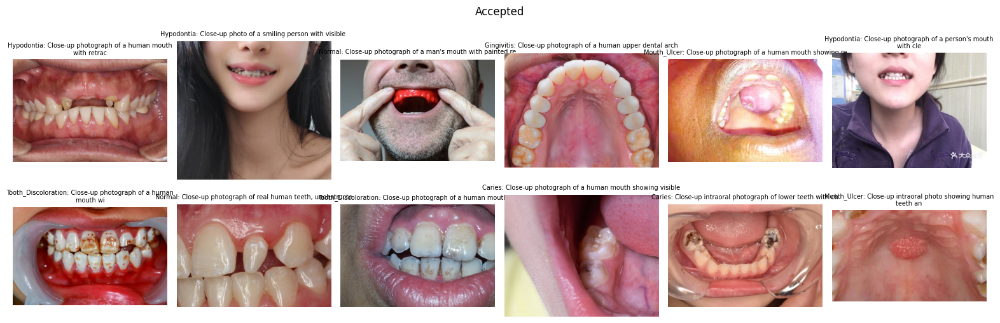

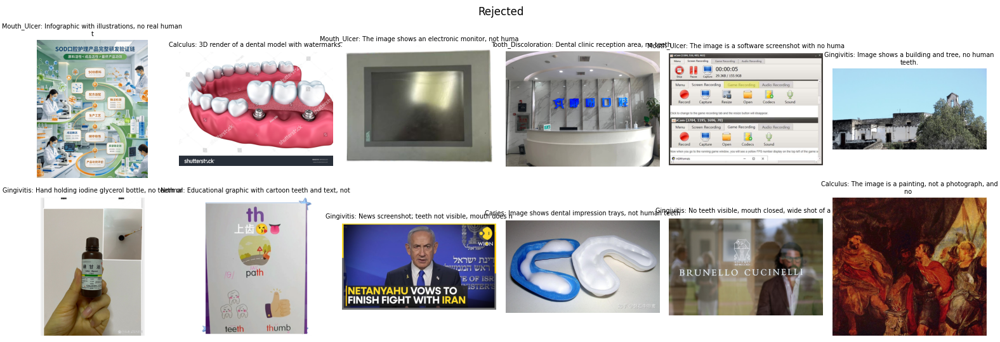

In [15]:
# Visual check: screening decisions
s = cand[cand.screened]
for name, part in [("Accepted", s[s.accepted]), ("Rejected", s[~s.accepted])]:
    smp = part.sample(min(12, len(part)), random_state=SEED)
    show_grid(smp.path.tolist(), titles=[f"{c}: {r}" for c, r in zip(smp.cls, smp.reason)], suptitle=name)

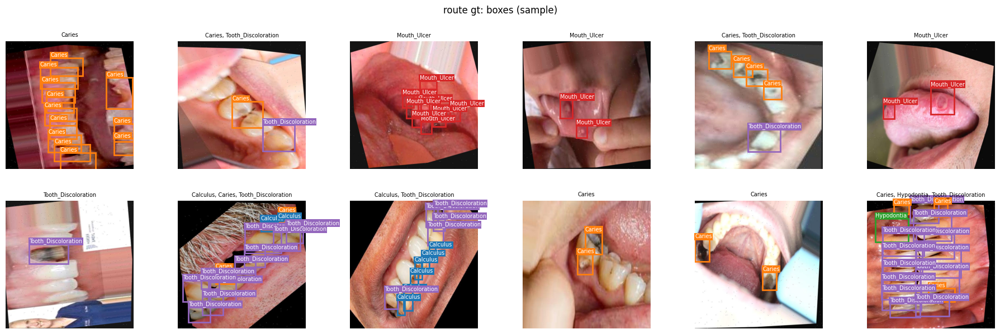

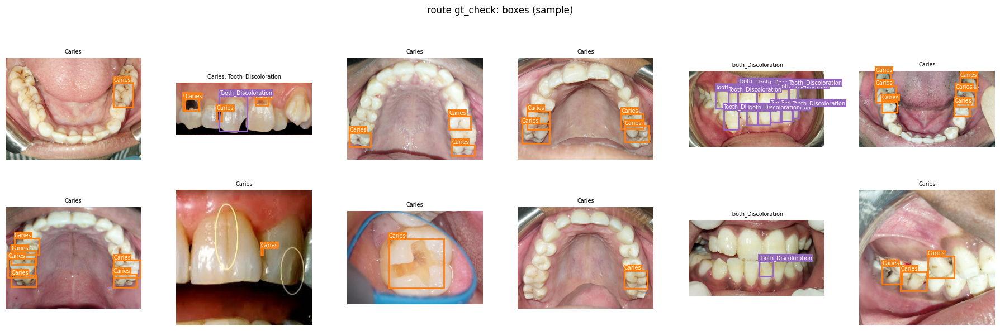

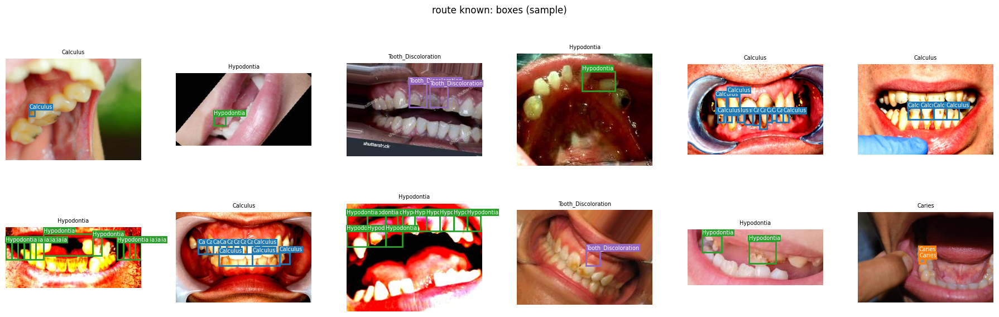

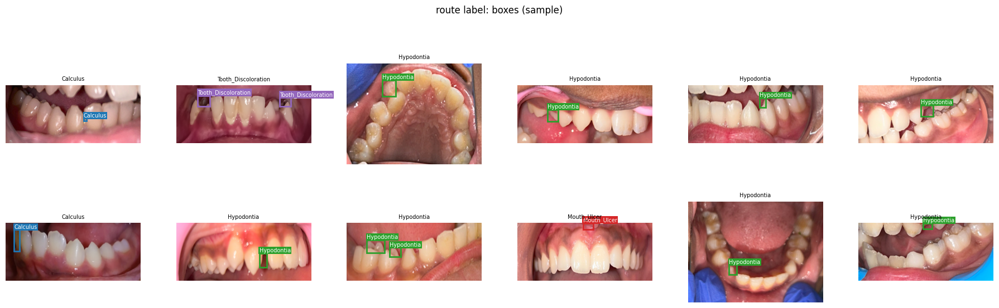

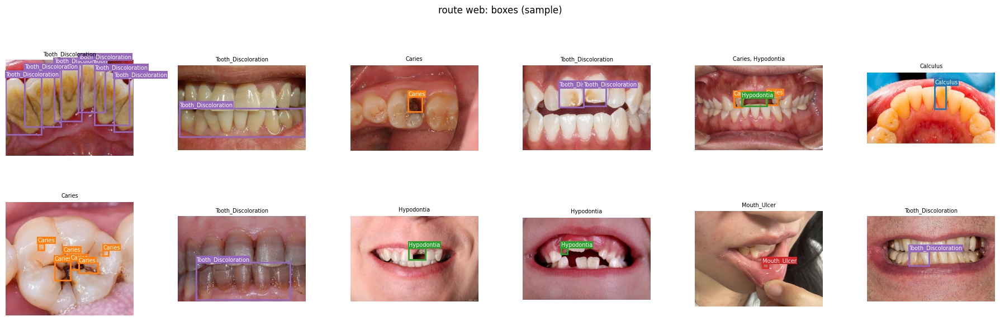

In [16]:
# Visual check: random boxed images per route (gt = dataset boxes; gt_check = human caries + model check; others = model)
for route in ["gt", "gt_check", "known", "label", "web"]:
    pool = [m for m in jobs if jobs[m][1] and route_name(ITEM[m]) == route]
    pick = random.sample(pool, min(12, len(pool)))
    if pick:
        show_grid([jobs[m][0] for m in pick], titles=[", ".join(LAB[m]) for m in pick],
                  boxes=[jobs[m][1] for m in pick], ncols=6, size=3, suptitle=f"route {route}: boxes (sample)")

## 7. Filter the labels and split

This cell sends no requests. It reads `labels.csv` and the `yolo/` folder and writes a cleaner, split copy to `yolo_filtered/`, leaving `yolo/` as it is. It needs only the setup cells in section 0, so you can run it on its own after a run has finished.

**Boxes dropped.** Qwen's boxes were checked by eye (2026-11-10), and these were the main problems:

| Rule | Why |
|---|---|
| Model `Hypodontia` boxes (`FILTER_DROP_MODEL_CLASSES`), except on kaggle's Hypodontia folder | Mostly false. On mendeley's side views, teeth that are out of frame or overlapping were marked as missing (39% of Upper Left / Right images vs 4% of Lower Front). |
| Model boxes over `FILTER_MAX_MODEL_AREA` of the image | Told that a condition must be boxed, the model sometimes boxed the whole photo. |
| Light-check boxes that hold more than half of a human caries box | The overlap rule in section 5 only catches a check box *inside* a caries box, not one wrapped *around* it. |
| Human boxes thinner than `FILTER_MIN_HUMAN_SIDE` | About 3 px at 640, too small to learn from (mostly dentalai). |

**Images dropped.**

- Every mendeley image that Qwen flagged with a condition (`FILTER_DROP_FLAGGED`). Its Calculus and Hypodontia findings were too unreliable. The images it called Normal stay as backgrounds.
- Images left with no boxes, or a kaggle image that lost the box of its folder's condition. They would otherwise become "Normal" backgrounds while still showing the condition.
- **Copies of roboflow photos.** About 2,800 kaggle_oral images (and a few others) are the same photos as roboflow_oral images, sometimes recoloured or flipped. The roboflow copy has human boxes, so the copy with model boxes is dropped.
- Extra Normal backgrounds in YOLO's train, so that they make up at most `BACKGROUND_SHARE` of it. A detector that sees too many empty images learns to stay quiet. These images are **not** lost: the classifier (stage 1, "issue or not") needs many healthy mouths and gets all of them.

**Split.** Copies of one photo are kept together in one split. Copies are Roboflow augmentations (same name before `.rf.`) and perceptual-hash near-duplicates within `DUP_MAX_HAMMING` bits. roboflow_oral itself holds the same photo under several names, with colour edits that change up to 8 bits. Groups chained beyond `MAX_EVAL_GROUP` images go to train. `val` and `test` (`VAL_SHARE` / `TEST_SHARE` each) get:

- **images with a condition**: only roboflow_oral groups (all boxes human), stratified by their rarest class, so the scores measure real accuracy, not agreement with Qwen;
- **Normal images**: a share of the Normal groups from every source, stratified by dataset, so the exam also asks "is this mouth healthy?". Only kaggle's `Normal` folder was filed by a person, so it gets a bigger share (`PERSON_NORMAL_SHARE` to val and to test), giving the person-only exam enough healthy mouths. The others were judged Normal by Qwen, which may have missed a small finding.

The `label_by` column says who decided each image's labels (`person`, `person (condition) + qwen (boxes)`, `person (caries) + qwen (other conditions)`, `qwen`). `val_person.txt` / `test_person.txt` and `data_person.yaml` give the same exam with only the `person` images, so you can report two scores. If they are close, Qwen's Normal labels are fine.

**Outputs.** `yolo_filtered/` (hard links, `train.txt` / `val.txt` / `test.txt`, `val_person.txt` / `test_person.txt`, `data.yaml`, `data_person.yaml`) and `labels_filtered.csv`. The CSV has one row per unique image, with `kept` (in the YOLO set), `in_classifier`, `has_issue` (the classifier target), `drop_reason`, `split`, `group`, `label_by` and the filtered 0/1 label columns, so the classifier can use the same labels. Backgrounds left out of YOLO by the cap have `drop_reason = background cap` and `in_classifier = True`. Their images are in `yolo_filtered/images` too, but not in `train.txt`.

In [17]:
# --- Settings ------------------------------------------------------------------------------------------------------
FILTER_DROP_MODEL_CLASSES = ["Hypodontia"]       # model boxes of these classes are dropped (kaggle known-folder boxes stay)
FILTER_DROP_FLAGGED = ["mendeley_noncaries"]     # datasets whose model-flagged images are dropped (their Normal ones stay)
FILTER_MAX_MODEL_AREA = 0.6                      # model boxes covering more than this share of the image are dropped
FILTER_CHECK_ENCLOSE = 0.5                       # light-check box holding more than this share of a human caries box: dropped
FILTER_MIN_HUMAN_SIDE = 0.005                    # human boxes thinner than this share of the image are dropped
BACKGROUND_SHARE = 0.10                          # max share of empty-label (Normal) images in train
VAL_SHARE, TEST_SHARE = 0.10, 0.10               # share of the eligible groups that go to val / test
PERSON_NORMAL_SHARE = 0.25                       # ... for Normal images filed by a person (kaggle's Normal folder), each
DUP_MAX_HAMMING = 8                              # pHash bits: Roboflow's colour augmentations of one photo differ by up to 8
MAX_EVAL_GROUP = 50                              # bigger (chained) photo groups always go to train
FILT_DIR = OUT / "yolo_filtered"
for d in [FILT_DIR / "images", FILT_DIR / "labels"]:
    d.mkdir(parents=True, exist_ok=True)

lab_all = pd.read_csv(OUT / "labels.csv", keep_default_na=False)
img = lab_all.drop_duplicates("md5").set_index("md5")
in_y = img.yolo != ""


def known_of(r):
    # kaggle folder classes for the known route ("Calculus / Hypodontia (class folder ...)" -> {Calculus, Hypodontia}).
    return set(r.orig_class.split(" (")[0].split(" / ")) if r.route == "known" else set()


def source_of(route, name, known):
    if route == "gt":
        return "human"
    if route == "gt_check":
        return "human" if name == "Caries" else "check"
    return "known" if name in known else "model"


def share_inside(a, b):
    # Share of YOLO box a (cls, cx, cy, w, h) that lies inside box b.
    ix = max(0.0, min(a[1] + a[3] / 2, b[1] + b[3] / 2) - max(a[1] - a[3] / 2, b[1] - b[3] / 2))
    iy = max(0.0, min(a[2] + a[4] / 2, b[2] + b[4] / 2) - max(a[2] - a[4] / 2, b[2] - b[4] / 2))
    return ix * iy / (a[3] * a[4]) if a[3] * a[4] > 0 else 0.0


def filter_image(m, r):
    # -> (kept rows, Counter of dropped boxes by reason, reason the whole image is dropped or None)
    rows = [(int(a[0]), *map(float, a[1:])) for a in
            (l.split() for l in (YOLO_DIR / "labels" / f"{m}.txt").read_text(encoding="utf-8").splitlines()) if a]
    if not rows:
        return rows, Counter(), None                                    # Normal background
    if r.dataset in FILTER_DROP_FLAGGED and r.route in ("label", "web"):
        return [], Counter(), f"model finding on {r.dataset}"
    known = known_of(r)
    src = [source_of(r.route, BOX_CLASSES[row[0]], known) for row in rows]
    human_caries = [row for row, s in zip(rows, src) if s == "human" and BOX_CLASSES[row[0]] == "Caries"]
    keep, why = [], Counter()
    for row, s in zip(rows, src):
        name, area = BOX_CLASSES[row[0]], row[3] * row[4]
        if s == "human":
            if min(row[3], row[4]) < FILTER_MIN_HUMAN_SIDE:
                why["tiny human box"] += 1; continue
        elif s != "known" and name in FILTER_DROP_MODEL_CLASSES:
            why[f"model {name} box"] += 1; continue
        elif area > FILTER_MAX_MODEL_AREA:
            why["model box over most of the image"] += 1; continue
        elif s == "check" and any(share_inside(g, row) > FILTER_CHECK_ENCLOSE for g in human_caries):
            why["check box around a human caries box"] += 1; continue
        keep.append(row)
    if not keep:
        return [], why, "all its boxes were dropped"                    # don't let it become a Normal background
    if any(BOX_CLASSES.index(k) not in {row[0] for row in keep} for k in known):
        return [], why, "known condition lost its box"
    return keep, why, None


FR, box_why, img_why = {}, Counter(), {}
for m, r in tqdm(img[in_y].iterrows(), total=int(in_y.sum()), desc="filter"):
    rows_, why, drop = filter_image(m, r)
    box_why += why
    if drop:
        img_why[m] = drop
    else:
        FR[m] = rows_

# --- Near-duplicates across datasets (perceptual hash, <= DUP_MAX_HAMMING bits) ------------------------------------
keep_md5 = sorted(FR)
ph_file = WORK / "phash_by_md5.pkl"
PH = pickle.loads(ph_file.read_bytes()) if ph_file.exists() else {}
todo_ph = [m for m in keep_md5 if m not in PH]
if todo_ph:
    def _ph(m):
        try:
            return m, phash64(load_rgb(YOLO_DIR / img.at[m, "yolo"], 256))
        except Exception:
            return m, None
    with ThreadPoolExecutor(IO_WORKERS) as ex:
        PH.update(dict(tqdm(ex.map(_ph, todo_ph), total=len(todo_ph), desc="phash")))
    ph_file.write_bytes(pickle.dumps(PH))

ph_ok = [m for m in keep_md5 if PH.get(m) is not None]
H = np.array([PH[m] for m in ph_ok], dtype=np.uint64)
_pop8 = np.array([bin(i).count("1") for i in range(256)], np.uint8)
dup_pairs = []
for s in range(0, len(H), 256):
    x = H[s:s + 256, None] ^ H[None, :]
    d = np.bitwise_count(x) if hasattr(np, "bitwise_count") else _pop8[x.view(np.uint8)].reshape(*x.shape, 8).sum(-1)
    i, j = np.nonzero(d <= DUP_MAX_HAMMING)
    i += s
    sel = i < j
    dup_pairs += [(ph_ok[a], ph_ok[b]) for a, b in zip(i[sel], j[sel])]

# kaggle_oral (and a few others) re-publish roboflow_oral photos. The roboflow copy has human boxes, so the other copy
# (model boxes on the same photo) is dropped.
for a, b in dup_pairs:
    ra, rb = img.at[a, "route"], img.at[b, "route"]
    if (ra == "gt") != (rb == "gt"):
        img_why[b if ra == "gt" else a] = "copy of a roboflow_oral photo"
keep_md5 = [m for m in keep_md5 if m not in img_why]

# --- Groups: copies of one photo must stay in one split ----------------------------------------------------------
# Joined: Roboflow augmentations of one source photo (same name before ".rf.", per dataset) and near-duplicates.
pos = {m: i for i, m in enumerate(keep_md5)}
e_i, e_j = [], []
for a, b in dup_pairs:
    if a in pos and b in pos:
        e_i.append(pos[a]); e_j.append(pos[b])
rf = lab_all[lab_all.md5.isin(pos) & lab_all.rel.str.contains(".rf.", regex=False)]
rf_stem = rf.dataset + "/" + rf.rel.str.rsplit("/", n=1).str[-1].str.split(".rf.").str[0]
for _, g in rf.md5.groupby(rf_stem):
    ids = sorted({pos[m] for m in g})
    e_i += ids[:-1]; e_j += ids[1:]
n_groups, grp = connected_components(coo_matrix((np.ones(len(e_i), np.int8), (e_i, e_j)), shape=(len(pos),) * 2),
                                     directed=False)
GROUP = dict(zip(keep_md5, grp))


def label_by(r, boxed):
    # Who decided this image's labels. "person" = fully human: roboflow boxes, or kaggle's Normal folder.
    if r.route == "gt":
        return "person"
    if r.route == "known":
        return "person (condition) + qwen (boxes)"
    if r.route == "gt_check":
        return "person (caries) + qwen (other conditions)"
    if r.dataset == "kaggle_oral" and r.orig_class.startswith("Normal") and not boxed:
        return "person"
    return "qwen"


LABEL_BY = {m: label_by(img.loc[m], bool(FR[m])) for m in keep_md5}


# --- Split ------------------------------------------------------------------------------------------------------------
# val / test get (a) groups whose every image has human boxes (roboflow), stratified by their rarest class, and
# (b) groups of Normal images (no boxes) from every source, stratified by dataset. kaggle's person-filed Normal
# folder gets PERSON_NORMAL_SHARE each, so the person-only exam has enough healthy mouths. Everything else is train.
gdf = pd.DataFrame({"md5": keep_md5, "group": grp, "route": [img.at[m, "route"] for m in keep_md5],
                    "dataset": [img.at[m, "dataset"] for m in keep_md5], "bg": [not FR[m] for m in keep_md5]})
g_small = gdf.groupby("group").size() <= MAX_EVAL_GROUP
human_only = gdf.groupby("group").route.agg(lambda s: set(s) == {"gt"}) & g_small
all_normal = gdf.groupby("group").bg.all() & g_small
g_dataset = gdf.groupby("group").dataset.first()
g_person = gdf.groupby("group").md5.agg(lambda s: all(LABEL_BY[m] == "person" for m in s))
cls_count = Counter(row[0] for m in keep_md5 for row in FR[m])
g_classes = gdf.groupby("group").md5.agg(lambda s: {row[0] for m in s for row in FR[m]})
SPLIT = {}
rng = np.random.default_rng(SEED)
eligible = list(human_only.index[human_only]) + list(all_normal.index[all_normal])
by_key = {}
for g in human_only.index[human_only]:
    by_key.setdefault(("boxed", BOX_CLASSES[min(g_classes[g], key=lambda c: cls_count[c])]), []).append(g)
for g in all_normal.index[all_normal]:
    by_key.setdefault(("normal", g_dataset[g], "person" if g_person[g] else "qwen"), []).append(g)
for key, gs in sorted(by_key.items()):
    gs = list(rng.permutation(gs))
    v_share, t_share = (PERSON_NORMAL_SHARE,) * 2 if key[0] == "normal" and key[2] == "person" else (VAL_SHARE, TEST_SHARE)
    n_val, n_test = round(len(gs) * v_share), round(len(gs) * t_share)
    for k, g in enumerate(gs):
        SPLIT[g] = "val" if k < n_val else "test" if k < n_val + n_test else "train"
gdf["split"] = gdf.group.map(SPLIT).fillna("train")
split_of = dict(zip(gdf.md5, gdf.split))

# --- Cap the Normal backgrounds in train ---------------------------------------------------------------------------
bg = [m for m in keep_md5 if not FR[m] and split_of[m] == "train"]
n_pos_train = sum(1 for m in keep_md5 if FR[m] and split_of[m] == "train")
n_bg = min(len(bg), int(BACKGROUND_SHARE / (1 - BACKGROUND_SHARE) * n_pos_train))
bg_keep = set(rng.choice(bg, n_bg, replace=False)) if n_bg else set()
for m in bg:
    if m not in bg_keep:
        img_why[m] = "background cap"
final = [m for m in keep_md5 if m not in img_why]                              # the YOLO set
# The classifier ("issue or not") needs many healthy mouths: it also gets the Normal images the cap left out of
# YOLO's train. They keep the split their photo group was given, so nothing leaks.
cls_extra = [m for m in keep_md5 if img_why.get(m) == "background cap"]
cls_all = final + cls_extra                                                      # the classifier set

# --- Write yolo_filtered ---------------------------------------------------------------------------------------------
want = {m: img.at[m, "yolo"] for m in cls_all}
for sub in ["images", "labels"]:
    for p in (FILT_DIR / sub).iterdir():
        if p.stem not in want or (sub == "images" and p.name != Path(want[p.stem]).name):
            p.unlink()


def write_filtered(m):
    dst = FILT_DIR / want[m]
    if not dst.exists():
        try:
            os.link(YOLO_DIR / want[m], dst)
        except OSError:
            shutil.copy2(YOLO_DIR / want[m], dst)
    (FILT_DIR / "labels" / f"{m}.txt").write_text(
        "".join(f"{c} {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}\n" for c, cx, cy, w, h in FR[m]), encoding="utf-8")


with ThreadPoolExecutor(IO_WORKERS) as ex:
    list(tqdm(ex.map(write_filtered, cls_all), total=len(cls_all), desc="yolo_filtered"))
for sp in ["train", "val", "test"]:
    (FILT_DIR / f"{sp}.txt").write_text("".join(f"./{want[m]}\n" for m in final if split_of[m] == sp), encoding="utf-8")
for sp in ["val", "test"]:                               # the same exam, person-labelled images only
    (FILT_DIR / f"{sp}_person.txt").write_text(
        "".join(f"./{want[m]}\n" for m in final if split_of[m] == sp and LABEL_BY[m] == "person"), encoding="utf-8")
(FILT_DIR / "classes.txt").write_text("\n".join(BOX_CLASSES) + "\n", encoding="utf-8")
for name, suffix, note in [("data.yaml", "", "all val / test images"),
                           ("data_person.yaml", "_person", "only val / test images labelled entirely by people")]:
    (FILT_DIR / name).write_text(
        "# Generated by qwen_clean_and_label.ipynb (section 7). Filtered labels, split by photo group.\n"
        f"# Scores on {note}. Boxed val / test images are roboflow_oral (human boxes); Normal ones come from every "
        "source (see label_by in labels_filtered.csv).\n"
        f"path: {FILT_DIR.as_posix()}\ntrain: train.txt\nval: val{suffix}.txt\ntest: test{suffix}.txt\n"
        f"nc: {len(BOX_CLASSES)}\nnames: {json.dumps(BOX_CLASSES)}\n", encoding="utf-8")

# --- labels_filtered.csv (one row per unique image; also usable for the classifier) --------------------------------
out = img.reset_index()[["dataset", "route", "rel", "md5", "orig_class", "labels", "state"]]
out["kept"] = out.md5.isin(set(final))                  # = in the YOLO set
out["in_classifier"] = out.md5.isin(set(cls_all))
out["drop_reason"] = [img_why.get(m, "") if m in FR or m in img_why else f"not in YOLO ({s})"
                      for m, s in zip(out.md5, out.state)]
out["split"] = out.md5.map(lambda m: split_of.get(m, "") if m in FR else "")
out["group"] = out.md5.map(lambda m: GROUP.get(m, -1))
filt_labels = {m: sorted({BOX_CLASSES[row[0]] for row in FR[m]}, key=LABELS.index) or ["Normal"] for m in FR}
out["labels_filtered"] = out.md5.map(lambda m: "|".join(filt_labels.get(m, [])))
for c in LABELS:
    out[c] = out.md5.map(lambda m: int(c in filt_labels.get(m, [])))
out["n_boxes_kept"] = out.md5.map(lambda m: len(FR[m]) if m in FR else 0)
out["has_issue"] = [int(bool(FR.get(m))) if m in FR else "" for m in out.md5]   # classifier target
out["label_by"] = [LABEL_BY.get(m) or label_by(img.loc[m], lb not in ("", "Normal"))
                   for m, lb in zip(out.md5, out.labels)]
out.to_csv(OUT / "labels_filtered.csv", index=False)

# --- Summary ---------------------------------------------------------------------------------------------------------
n_train = sum(split_of[m] == "train" for m in final)
n_bg_train = sum(1 for m in final if not FR[m] and split_of[m] == "train")
print(f"YOLO before: {int(in_y.sum())} images | after: {len(final)} images "
      f"(Normal backgrounds: {n_bg_train} in train = {n_bg_train / max(1, n_train):.0%} of train, "
      f"{sum(1 for m in final if not FR[m] and split_of[m] != 'train')} in val / test)")
print("boxes dropped:", dict(box_why))
print("images dropped:", dict(Counter(img_why.values())))
before = Counter(BOX_CLASSES[int(l.split()[0])] for m in img[in_y].index
                 for l in (YOLO_DIR / "labels" / f"{m}.txt").read_text(encoding="utf-8").splitlines() if l.strip())
tab = pd.DataFrame({"boxes before": pd.Series(before)})
for sp in ["train", "val", "test"]:
    tab[f"{sp} boxes"] = pd.Series(Counter(BOX_CLASSES[row[0]] for m in final if split_of[m] == sp for row in FR[m]))
    tab[f"{sp} images"] = pd.Series(Counter(BOX_CLASSES[c] for m in final if split_of[m] == sp
                                            for c in {row[0] for row in FR[m]}))
tab.loc["Normal (no boxes)", [f"{sp} images" for sp in ["train", "val", "test"]]] = [
    sum(1 for m in final if split_of[m] == sp and not FR[m]) for sp in ["train", "val", "test"]]
display(tab.fillna(0).astype(int))
for sp in ["train", "val", "test"]:
    n_sp = [m for m in final if split_of[m] == sp]
    c_sp = [m for m in cls_all if split_of[m] == sp]
    print(f"{sp}: YOLO {len(n_sp)} images ({sum(LABEL_BY[m] == 'person' for m in n_sp)} labelled entirely by people) | "
          f"classifier {len(c_sp)} images: {sum(1 for m in c_sp if FR[m])} issue, {sum(1 for m in c_sp if not FR[m])} healthy")
sizes = gdf.group.value_counts()
print(f"{n_groups} photo groups (largest {sizes.max()} images, {(sizes > 1).sum()} with more than one); "
      f"eligible for val / test: {int(human_only.sum())} roboflow groups + {int(all_normal.sum())} Normal groups -> {FILT_DIR}")

yolo_filtered: 100%|██████████| 31326/31326 [00:08<00:00, 3577.44it/s]


YOLO before: 45506 images | after: 31326 images (2657 backgrounds = 10% of train)
boxes dropped: {'tiny human box': 588, 'check box around a human caries box': 83, 'model Hypodontia box': 303, 'model box over most of the image': 54}
images dropped: {'all its boxes were dropped': 251, 'model finding on mendeley_noncaries': 4568, 'copy of a roboflow_oral photo': 2774, 'background cap': 6587}


,boxes before,train boxes,train images,val boxes,val images,test boxes,test images
Caries,41635,35476,10749,2600,845,2761,811
Tooth_Discoloration,67868,50692,8520,5003,868,5536,885
Hypodontia,10608,4693,2500,518,288,845,397
Mouth_Ulcer,11894,9628,4711,1066,550,1055,568
Calculus,28291,14116,3628,1782,429,1495,415


images per split: {'train': 26578, 'test': 2447, 'val': 2301}
20430 photo groups (largest 235 images, 6693 with more than one); 7367 fully human groups eligible for val / test -> C:\Users\Dani\Documents\School\AI Inno W DL\Deep-Learning-WIU\data\processed\qwen_labels\Daniel\yolo_filtered


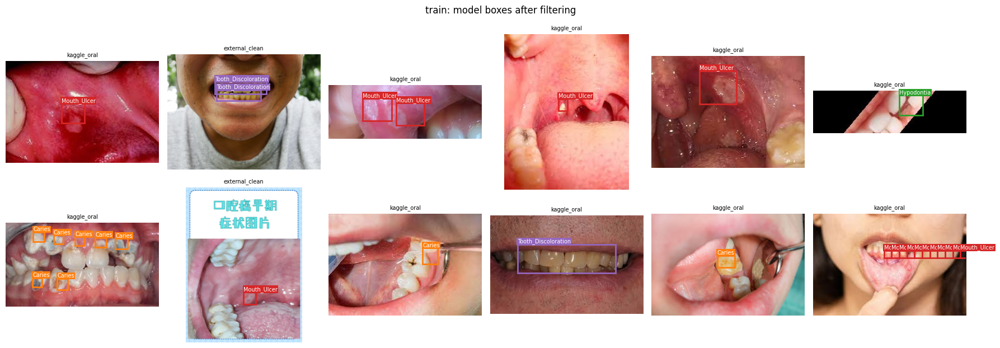

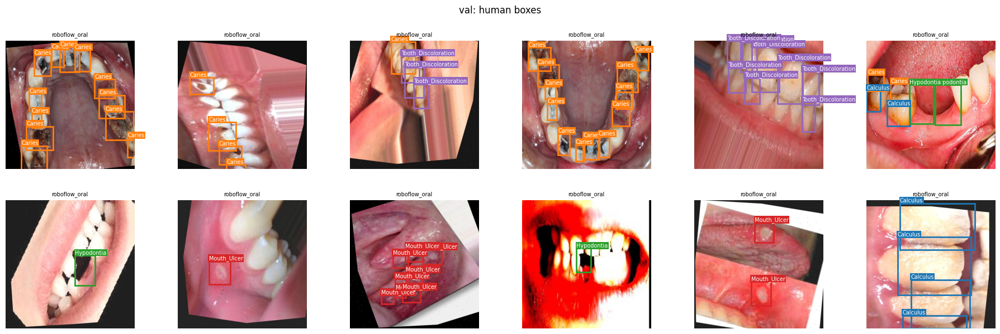

In [18]:
# Visual check: filtered set (train images with model boxes; val images with human boxes)
for name, pool in [("train: model boxes after filtering",
                    [m for m in final if split_of[m] == "train" and FR[m] and img.at[m, "route"] in ("known", "label", "web")]),
                   ("val: human boxes", [m for m in final if split_of[m] == "val"])]:
    pick = random.Random(SEED).sample(pool, min(12, len(pool)))
    show_grid([FILT_DIR / want[m] for m in pick], titles=[img.at[m, "dataset"] for m in pick],
              boxes=[FR[m] for m in pick], ncols=6, size=3, suptitle=name)

## 8. Zip the dataset

This cell packs the section 7 output into one zip for both stages, the classifier ("issue or not") and YOLO ("where"), you can share or upload (e.g. to Colab): `data/processed/qwen_labels/Daniel/oral_dataset.zip`, about 2.8 GB. It needs section 7 to have run in this session.

```
oral_dataset/
  README.md        how the data was made, class ids, images per split
  data.yaml        YOLO config with relative paths: works wherever the zip is unzipped; trains on yolo_train.txt
  yolo_train.txt   YOLO's train images (healthy mouths capped at 10%); images/train also holds the extra healthy ones for the classifier
  data_person.yaml same, but val / test hold only images labelled entirely by people (+ val_person.txt, test_person.txt)
  classes.txt
  labels.csv       one row per image: image path, split, has_issue (classifier target), in_yolo, label_by, source dataset, 0/1 label columns, boxes_by
  images/train|val|test/<md5>.<ext>
  labels/train|val|test/<md5>.txt   empty file = Normal
```

The images are stored as they are, because JPEG / PNG files don't compress further. The text files are compressed. The zip is written to a `.part` file and renamed only when complete, so an interrupted run never leaves a broken zip. Its comment holds a fingerprint of the images, labels, split and text files. When nothing has changed, the cell keeps the existing zip and finishes in about a second. Set `QWEN_MAKE_ZIP=0` (or `--no-zip` in the runner) to skip it.

After unzipping: `yolo detect train data=oral_dataset/data.yaml model=yolo11n.pt imgsz=640`. Checked with Ultralytics 8.3: it finds every image and label in the unzipped folder.

In [ ]:
import zipfile
from datetime import date

ZIP_PATH = Path(_env("QWEN_ZIP_PATH", str(OUT / "oral_dataset.zip")))
ZIP_ROOT = "oral_dataset"                         # top folder inside the zip
MAKE_ZIP = _env("QWEN_MAKE_ZIP", True, bool)

SPLITS = ["train", "val", "test"]
z_files = {m: f"{split_of[m]}/{m}{Path(want[m]).suffix}" for m in cls_all}     # path below images/
z_labels = {m: "".join(f"{c} {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}\n" for c, cx, cy, w, h in FR[m]) for m in cls_all}
BOXES_BY = {"gt": "human", "gt_check": "human (caries) + model (other classes)", "known": "model", "label": "model",
            "web": "model"}
z_csv = out[out.in_classifier].copy()
z_csv.insert(0, "image", z_csv.md5.map(lambda m: "images/" + z_files[m]))
z_csv["boxes_by"] = z_csv.route.map(BOXES_BY)
z_csv["in_yolo"] = z_csv.kept.astype(int)
z_csv = z_csv.rename(columns={"rel": "source_file", "labels_filtered": "labels", "labels": "labels_before_filter"})
z_csv = z_csv[["image", "split", "has_issue", "in_yolo", "label_by", "dataset", "source_file", "orig_class", "labels"] + LABELS
              + ["n_boxes_kept", "boxes_by", "route", "group", "md5"]].sort_values(["split", "image"])
z_yolo_train = "".join(f"./images/{z_files[m]}\n" for m in sorted(final, key=z_files.get)
                       if split_of[m] == "train")
z_person = {sp: "".join(f"./images/{z_files[m]}\n" for m in sorted(final, key=z_files.get)
                        if split_of[m] == sp and LABEL_BY[m] == "person") for sp in ["val", "test"]}

counts = pd.DataFrame({sp: pd.Series(Counter(BOX_CLASSES[c] for m in final if split_of[m] == sp
                                             for c in {row[0] for row in FR[m]})) for sp in SPLITS}
                      ).reindex(BOX_CLASSES).fillna(0).astype(int)
counts.loc["Normal (no boxes)"] = [sum(1 for m in final if split_of[m] == sp and not FR[m]) for sp in SPLITS]
counts.loc["all images"] = [sum(1 for m in final if split_of[m] == sp) for sp in SPLITS]
counts.loc["classifier: issue"] = [sum(1 for m in cls_all if split_of[m] == sp and FR[m]) for sp in SPLITS]
counts.loc["classifier: healthy"] = [sum(1 for m in cls_all if split_of[m] == sp and not FR[m]) for sp in SPLITS]
counts.loc["labelled entirely by people"] = [sum(1 for m in final if split_of[m] == sp and LABEL_BY[m] == "person")
                                             for sp in SPLITS]

def md_table(df):
    # Markdown table without the optional tabulate package.
    head = "| | " + " | ".join(map(str, df.columns)) + " |\n|---|" + "---:|" * len(df.columns) + "\n"
    return head + "".join(f"| {i} | " + " | ".join(map(str, r)) + " |\n" for i, r in zip(df.index, df.values))


YAML_HEAD = ("# YOLO dataset. There is no 'path' key on purpose: Ultralytics then uses this file's folder as the root,\n"
             "# so the dataset works wherever it is unzipped.\n")
YAML_TAIL = f"nc: {len(BOX_CLASSES)}\nnames: {json.dumps(BOX_CLASSES)}\n"
z_yaml = YAML_HEAD + "train: yolo_train.txt\nval: images/val\ntest: images/test\n" + YAML_TAIL
z_yaml_person = (YAML_HEAD + "# val / test: only the images whose labels were decided entirely by people.\n"
                 "train: yolo_train.txt\nval: val_person.txt\ntest: test_person.txt\n" + YAML_TAIL)
z_readme = f"""# Oral condition dataset (issue classifier + YOLO detector)

Built {{BUILT}} by `models/classifier/notebooks/Daniel/qwen_clean_and_label.ipynb` (sections 6-8).

## Layout

```
{ZIP_ROOT}/
  data.yaml          YOLO config (paths are relative to this file); YOLO trains on yolo_train.txt
  yolo_train.txt     YOLO's train images: images/train minus the extra healthy mouths (kept at 10% for YOLO)
  data_person.yaml   same, but val / test hold only images labelled entirely by people
  val_person.txt, test_person.txt   the image lists data_person.yaml uses
  classes.txt        class ids 0-{len(BOX_CLASSES) - 1}
  labels.csv         one row per image: split, has_issue (classifier target), in_yolo, label_by, source,
                     0/1 label columns, who drew the boxes
  images/train|val|test/<md5>.<ext>
  labels/train|val|test/<md5>.txt   YOLO rows: class cx cy w h (0-1); empty file = Normal (no condition)
```

## Classes

{chr(10).join(f"- `{i}` {c}" for i, c in enumerate(BOX_CLASSES))}

`Normal` is not a class: a Normal image has an empty label file.

## Images per split (an image counts once per class it contains; YOLO rows count the YOLO set)

{md_table(counts)}

## Who decided the labels (`label_by` in labels.csv)

- **val and test**: every image with a condition is from `roboflow_oral`, whose boxes were all drawn by people.
  The Normal images (about 10% of each source's Normal images) come from every source. Only kaggle's `Normal`
  folder was filed by a person; the others were judged Normal by Qwen (for `dentalai` / `zenodo`: people marked no
  caries, Qwen checked the other conditions). Qwen may have missed a small finding on some of them.
- **train** mixes human boxes (`roboflow_oral`; the caries boxes of `dentalai` / `zenodo`) with boxes predicted by
  Qwen (`qwen3.8-flash-next-mxfp4`) for `kaggle_oral`, `mendeley_noncaries` and web images, after filtering out
  the kinds of boxes that proved unreliable. The `boxes_by` column says which.
- Copies of one photo (Roboflow augmentations, re-uploads, kaggle_oral copies of roboflow_oral photos) are always in
  the same split.

## Two stages

1. **Classifier: issue or not.** Train on every row of `labels.csv` with `split == "train"`; the target is
   `has_issue` (1 = at least one condition, 0 = healthy). It gets all the healthy mouths (see the table).
2. **YOLO: where.** Runs on the images the classifier flags. It trains on `yolo_train.txt`, where healthy mouths
   are capped at about 10%: a detector that sees too many empty images learns to stay quiet. The extra healthy
   images are in `images/train` with empty label files (`in_yolo = 0`), so they never reach YOLO.

Both stages share val / test, so the whole pipeline can be scored on the same test images.

## Use

YOLO (Ultralytics): `yolo detect train data=data.yaml model=yolo11n.pt imgsz=640`

Report two scores on the test set:

- all test images: `yolo detect val model=best.pt data=data.yaml split=test`
- only person-labelled test images: `yolo detect val model=best.pt data=data_person.yaml split=test`

If they are close, Qwen's Normal labels are fine. If the first is clearly lower, look at the Normal images where the
model found something: Qwen may have missed it.

Classifier: read `labels.csv`, load `image`, use `has_issue` as the target (or the `{"`, `".join(LABELS)}`
columns for a multi-label model), and report the same two scores (all test rows, and test rows with
`label_by == "person"`). Train has about 3 issue images per healthy one: use class weights or a balanced sampler.
"""
# Same images, labels, split and text files -> same fingerprint -> the existing zip is kept.
z_csv_text = z_csv.to_csv(index=False)
fingerprint = hashlib.sha1("".join(
    [f"{z_files[m]}\t{z_labels[m]}\n" for m in sorted(cls_all)]
    + [z_csv_text, z_yaml, z_yaml_person, z_readme, z_yolo_train, *z_person.values()]).encode()).hexdigest()
z_readme = z_readme.replace("{BUILT}", date.today().isoformat())
old_fp = None
if ZIP_PATH.exists():
    try:
        with zipfile.ZipFile(ZIP_PATH) as zf:
            old_fp = zf.comment.decode()
    except zipfile.BadZipFile:
        pass

if not MAKE_ZIP:
    print("zip skipped (MAKE_ZIP = False)")
elif old_fp == fingerprint:
    print(f"zip is up to date ({ZIP_PATH.stat().st_size / 1e9:.2f} GB) -> {ZIP_PATH}")
else:
    ZIP_PATH.parent.mkdir(parents=True, exist_ok=True)
    tmp = ZIP_PATH.with_name(ZIP_PATH.name + ".part")          # renamed when complete: no half-written zip
    with zipfile.ZipFile(tmp, "w", allowZip64=True) as zf:
        text = dict(compress_type=zipfile.ZIP_DEFLATED, compresslevel=6)
        zf.writestr(f"{ZIP_ROOT}/README.md", z_readme, **text)
        zf.writestr(f"{ZIP_ROOT}/data.yaml", z_yaml, **text)
        zf.writestr(f"{ZIP_ROOT}/data_person.yaml", z_yaml_person, **text)
        zf.writestr(f"{ZIP_ROOT}/yolo_train.txt", z_yolo_train, **text)
        for sp, lines in z_person.items():
            zf.writestr(f"{ZIP_ROOT}/{sp}_person.txt", lines, **text)
        zf.writestr(f"{ZIP_ROOT}/classes.txt", "\n".join(BOX_CLASSES) + "\n", **text)
        zf.writestr(f"{ZIP_ROOT}/labels.csv", z_csv_text, **text)
        for m in tqdm(sorted(cls_all, key=z_files.get), desc="zip"):
            # JPEG / PNG / WebP are already compressed: stored as they are (fast, same size)
            zf.write(FILT_DIR / want[m], f"{ZIP_ROOT}/images/{z_files[m]}", compress_type=zipfile.ZIP_STORED)
            zf.writestr(f"{ZIP_ROOT}/labels/{Path(z_files[m]).with_suffix('.txt').as_posix()}", z_labels[m], **text)
        zf.comment = fingerprint.encode()
    os.replace(tmp, ZIP_PATH)
    print(f"wrote {len(cls_all)} images ({ZIP_PATH.stat().st_size / 1e9:.2f} GB) -> {ZIP_PATH}")
display(counts)

## Notes

- **Class list.** The YOLO classes are the five conditions in `shared/conditions.yaml` (calculus, caries, hypodontia, mouth_ulcer, tooth_discoloration). `normal` is an empty label file. `Gingivitis` and `Others` were removed. The YOLO ids here are not the classifier's ids, so map them by name before mixing the two.
- **Human vs model boxes.** `labels.csv` has `n_human_boxes` next to `n_boxes`. `roboflow_oral` boxes are all human. `dentalai` / `zenodo` caries boxes are human, and any other box on those images comes from the light check. Everything else comes from the model.
- **Measured effect of the new label prompt** (thinking off, high-confidence findings only, 2026-11-10, 130 images from kaggle / mendeley with no hint). kaggle `Normal` labelled Normal: 12% with the old prompt → 70% with the new one. Caries on kaggle `Normal`: 48% → 3%. Caries on caries-free mendeley: 37% → 8%. Caries on kaggle `tooth discoloration`: 49% → 10%. Calculus still gets confused with fissure staining and caries, and the `known` route sidesteps this for kaggle's Calculus folder.
- **Re-running.** Change a prompt and you should delete the matching `data/interim/Daniel/qwen_pipeline/<step>__<model>.jsonl` (or bump its cache name), or answers produced with the old prompt are reused. `MIN_CONFIDENCE`, `MAX_BOXES`, `NMS_IOU` and `COORD_MODE` are applied when the answers are read, so changing them needs no new requests.
- **Old outputs.** The caches from the earlier version (`label_v2`, `boxes`) are no longer read, and stay on disk. A copy of everything from before this version, including the YOLO folder and `box_review.csv`, is in `data/backups/qwen_pipeline_20261110/`.
- **kaggle_oral copies roboflow_oral.** About 2,700 of kaggle's images are near-copies of roboflow_oral photos (found by perceptual hash in section 7). Never put the two in different splits, and prefer roboflow's human boxes.